# EXPERIMENT 3 - Exploratory Data Analysis Through Statistical Visualization
### of Distributions, Relationships, Correlations, and Outliers

**Aim:** perform a complete, reproducible Exploratory Data Analysis (EDA) on a
real-world dataset using statistical visualizations.

**Objectives**

1. Load, inspect and document a real-world dataset.
2. Detect and clean quality problems (missing values, duplicates, impossible values).
3. Visualise and interpret the **five** canonical distribution shapes.
4. Analyse relationships between variables with scatter plots.
5. Compute Pearson's correlation coefficient (by library **and** by formula),
   build a correlation matrix and a heatmap.
6. Fit and evaluate a simple linear regression model.
7. Detect outliers with the Interquartile-Range (IQR) rule and box plots.
8. Produce additional statistical visualizations (pair plot, violin plots,
   Q-Q plots, count plots, bar charts).
9. Document findings, limitations and answers to common viva questions.

**Main dataset:** Palmer Penguins (real observations, documented source below).
Synthetic data is used **only** where a pattern cannot be demonstrated with the
real dataset, and every such use is clearly labelled.

**How to run:** upload this file to Google Colab (*File -> Upload notebook*)
and use *Runtime -> Run all*, or open it in Jupyter and run top-to-bottom. The
notebook carries its own `src/` modules and dataset, detects Google Colab,
Kaggle and local Python by itself and needs no manual path changes. Plots and
reports are written to `/content/outputs` (Colab), `/kaggle/working/outputs`
(Kaggle) or `<project>/outputs` (local).


In [1]:
# ============================================================
# 0. ENVIRONMENT SETUP  (local Python / Google Colab / Kaggle)
# ============================================================
import importlib.util
import os
import subprocess
import sys
import zipfile
from pathlib import Path

# --- detect where this notebook is running -------------------
try:
    import google.colab  # type: ignore  # noqa: F401
    IS_COLAB = True
except Exception:
    IS_COLAB = False

IS_KAGGLE = Path("/kaggle/input").exists() or os.environ.get("KAGGLE_KERNEL_RUN_TYPE") is not None
IS_LOCAL = not (IS_COLAB or IS_KAGGLE)
ENV_NAME = "Google Colab" if IS_COLAB else ("Kaggle" if IS_KAGGLE else "Local Python")

print(f"Environment  : {ENV_NAME}")
print(f"Python       : {sys.version.split()[0]}")
print(f"Working dir  : {Path.cwd()}")

# --- install only missing libraries (Google Colab convenience) ---
REQUIRED = ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "sklearn"]
missing = [m for m in REQUIRED if importlib.util.find_spec(m) is None]
if missing:
    print("Missing libraries:", missing)
    if IS_COLAB:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                               "pandas", "numpy", "matplotlib", "seaborn",
                               "scipy", "scikit-learn"])
        print("Libraries installed.")
    else:
        print("Install them with:  pip install -r requirements.txt")
else:
    print("All required libraries are already installed.")


Environment  : Local Python
Python       : 3.11.9
Working dir  : D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3
All required libraries are already installed.


In [2]:
# ============================================================
# 0b. PROJECT ARCHIVE EMBEDDED IN THIS NOTEBOOK
#     Restores src/ (analysis modules) and data/raw/penguins.csv on a
#     fresh Google Colab / Kaggle runtime, so "Runtime -> Run all"
#     works without uploading any extra file.
# ============================================================
_EDA_PROJECT_ARCHIVE_ZIP_BYTES = 63035

EDA_PROJECT_ARCHIVE_B64 = "".join([
    "...",
])

print(
    f"Embedded project archive ready: "
    f"{_EDA_PROJECT_ARCHIVE_ZIP_BYTES / 1024:.1f} KB "
    f"(used only when src/ or data/ are missing)."
)


Embedded project archive ready: 61.6 KB (used only when src/ or data/ are missing).


In [3]:
# --- locate the project folder (works on any machine / Colab / Kaggle) ---
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    return start


def _extract_archive(archive: Path, destination: Path) -> None:
    with zipfile.ZipFile(archive) as zf:
        zf.extractall(destination)


ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# --- fresh runtime (Google Colab / Kaggle)? restore the project files ------
if not (ROOT / "src").is_dir() or not (ROOT / "data" / "raw").is_dir():
    workspace = Path.cwd()

    # 1) archive embedded in this notebook - fully automatic
    if globals().get("EDA_PROJECT_ARCHIVE_B64"):
        import base64 as _b64

        embedded = workspace / "_eda_project_embedded.zip"
        embedded.write_bytes(_b64.b64decode(EDA_PROJECT_ARCHIVE_B64))
        _extract_archive(embedded, workspace)
        embedded.unlink(missing_ok=True)
        print("Project code and dataset restored from the embedded archive.")

    # 2) a ZIP already present in the working directory (Files pane / input dataset)
    if not (workspace / "src").is_dir():
        for candidate in sorted(workspace.glob("*.zip")):
            try:
                with zipfile.ZipFile(candidate) as zf:
                    names = zf.namelist()
            except zipfile.BadZipFile:
                continue
            if any(name.startswith("src/") for name in names):
                _extract_archive(candidate, workspace)
                print(f"Project restored from {candidate.name}")
                break

    # 3) last resort - interactive upload (only when nothing else worked)
    if not (workspace / "src").is_dir() and IS_COLAB:
        from google.colab import files  # type: ignore
        print("No project files found. Upload the project ZIP (eda_experiment3_outputs.zip)")
        print("or at least the dataset CSV (e.g. penguins.csv):")
        uploaded = files.upload()
        for name, content in uploaded.items():
            Path(name).write_bytes(content)
            if name.lower().endswith(".zip"):
                _extract_archive(Path(name), workspace)

    ROOT = find_project_root()
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))

# --- create every output directory (idempotent) ---------------
for sub in ["data/raw", "data/processed", "outputs/plots", "outputs/reports", "outputs/logs"]:
    (ROOT / sub).mkdir(parents=True, exist_ok=True)

print("Project root  :", ROOT)
print("Dataset folder:", ROOT / "data" / "raw")


Project root  : D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3
Dataset folder: D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\data\raw


## 2. Dataset source and description

**Palmer Penguins** - measurements collected at Palmer Station, Antarctica
(Gorman, Williams & Fraser, 2014), packaged by Dr. Allison Horst
(`palmerpenguins` R package, **CC0 1.0** public-domain dedication).

| Column | Type | Meaning |
|---|---|---|
| `species` | categorical | Adelie, Chinstrap or Gentoo penguin |
| `island` | categorical | Torgersen, Biscoe or Dream island |
| `bill_length_mm` | numerical | length of the bill (mm) |
| `bill_depth_mm` | numerical | depth of the bill (mm) |
| `flipper_length_mm` | numerical | length of the flipper (mm) |
| `body_mass_g` | numerical | body mass (g) |
| `sex` | categorical | male / female (some missing) |
| `year` | ordinal | 2007, 2008 or 2009 |

* Local source file: `data/raw/penguins.csv`
* Download URL: `https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv`
* Citation: Gorman KB, Williams TD, Fraser WR (2014), *PLoS ONE* 9(3): e109091,
  DOI 10.1371/journal.pone.0109091
* 344 rows x 8 columns with real missing values - ideal for a realistic EDA.


In [4]:
# ============================================================
# 1. LIBRARIES AND CONFIGURATION
# ============================================================
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src import data_cleaning, correlation_analysis, distribution_analysis
from src import outlier_analysis, regression_analysis, relationship_analysis
from src.data_loader import (
    describe_environment, find_kaggle_input, initial_inspection,
    kaggle_credentials_available, list_columns, load_dataset,
    missing_report, resolve_dataset_path,
)
from src.visualization import apply_style, save_figure, subplots

apply_style()

SEED = 42                       # fixed seed -> fully reproducible results
np.random.seed(SEED)
DATASET_PATH = None             # e.g. "data/raw/penguins.csv" (None = auto-detect)
KAGGLE_DATASET_SLUG = ""        # e.g. "owner/penguins" when running on Kaggle
X_COL, Y_COL = "flipper_length_mm", "body_mass_g"     # regression pair
TEST_SIZE, RANDOM_STATE = 0.25, 42

print(json.dumps(describe_environment(), indent=2))
print("Kaggle credentials available:", kaggle_credentials_available(),
      "(token values are never displayed)")


{
  "python_version": "3.11.9",
  "platform": "Windows-10-10.0.26300-SP0",
  "machine": "AMD64",
  "working_directory": "D:\\Opean Ai\\Data-Visualization-Lab-Experiments\\experiment-3",
  "google_colab": false,
  "kaggle": false,
  "libraries": {
    "pandas": "3.0.5",
    "numpy": "2.4.6",
    "matplotlib": "3.11.2",
    "seaborn": "0.13.2",
    "scipy": "1.17.1",
    "sklearn": "1.9.0"
  }
}
Kaggle credentials available: True (token values are never displayed)


## 3. Dataset loading

The loader resolves the dataset in a fixed order: explicit path ->
environment variable `EDA_DATASET_PATH` -> `data/raw/penguins.csv` -> a mounted
Kaggle dataset (`/kaggle/input`) -> an interactive upload in Google Colab.
No machine-specific path is hard-coded.


In [5]:
# Kaggle: point to a mounted dataset slug when needed (never downloads if mounted)
if IS_KAGGLE and KAGGLE_DATASET_SLUG:
    os.environ["EDA_KAGGLE_DATASET"] = KAGGLE_DATASET_SLUG
    print("Kaggle input dataset slug:", KAGGLE_DATASET_SLUG)

raw = load_dataset(DATASET_PATH, root=ROOT, allow_upload=IS_COLAB)
print("Source file :", raw.attrs.get("source_path"))
print("Dimensions  :", raw.shape, "(rows x columns)")
print()
print("First 10 rows:")
raw.head(10)


Source file : D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\data\raw\penguins.csv
Dimensions  : (344, 8) (rows x columns)

First 10 rows:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female,2007
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,male,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007


In [6]:
print("Last 5 rows:")
raw.tail(5)


Last 5 rows:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


In [7]:
print("Column names      :", list(raw.columns))
print()
print("Data types:")
print(raw.dtypes)
print()
print("Unique values per column:")
print(raw.nunique(dropna=True))
print()
print("Duplicate rows    :", int(raw.duplicated().sum()))
print("Total missing     :", int(raw.isna().sum().sum()))
info = initial_inspection(raw)
print("Memory usage (MB) :", info["memory_mb"])


Column names      : ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']

Data types:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

Unique values per column:
species                3
island                 3
bill_length_mm       164
bill_depth_mm         80
flipper_length_mm     55
body_mass_g           94
sex                    2
year                   3
dtype: int64

Duplicate rows    : 0
Total missing     : 19
Memory usage (MB) : 0.078


## 4. Data-quality analysis

Before any analysis we check: missing values, duplicate rows, constant columns,
suspicious or impossible values, and categorical inconsistencies such as
accidental whitespace (`"male "` would silently become a third sex category).


In [8]:
missing = missing_report(raw)
print("Missing values per column:")
display(missing)
print()
print("Total missing values :", int(raw.isna().sum().sum()))
print("Duplicate rows       :", int(raw.duplicated().sum()))
print("Rows x Columns       :", raw.shape)


Missing values per column:


,missing_count,missing_percent,dtype,unique_values
sex,11,3.20,str,2
bill_depth_mm,2,0.58,float64,80
flipper_length_mm,2,0.58,float64,55
bill_length_mm,2,0.58,float64,164
body_mass_g,2,0.58,float64,94
island,0,0.00,str,3
species,0,0.00,str,3
year,0,0.00,int64,3



Total missing values : 19
Duplicate rows       : 0
Rows x Columns       : (344, 8)


In [9]:
print("Numerical summary statistics:")
display(raw.describe().T)


Numerical summary statistics:


,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0
year,344.0,2008.029070,0.818356,2007.0,2007.000,2008.00,2009.0,2009.0


In [10]:
print("Categorical summary statistics:")
display(raw.describe(include="all").T)


Categorical summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,3,Adelie,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,344,3,Biscoe,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bill_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,200.915205,14.061714,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,333,2,male,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,344.0,NaN,NaN,NaN,2008.02907,0.818356,2007.0,2007.0,2008.0,2009.0,2009.0


In [11]:
# --- data-quality checks with the shared cleaning module ---
from src.data_cleaning import (
    check_numeric_ranges, find_constant_columns, find_duplicate_rows,
    strip_categorical_whitespace,
)

VALID_RANGES = {
    "bill_length_mm": (25.0, 70.0),
    "bill_depth_mm": (10.0, 25.0),
    "flipper_length_mm": (150.0, 250.0),
    "body_mass_g": (2000.0, 7000.0),
    "year": (2007, 2009),
}
POSITIVE_COLUMNS = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

print("Constant columns         :", find_constant_columns(raw) or "none")
print("Duplicate rows           :", len(find_duplicate_rows(raw)))
_trimmed, changed = strip_categorical_whitespace(raw)
print("Columns needing trimming :", changed or "none")
print("Impossible-value findings:", check_numeric_ranges(raw, VALID_RANGES, POSITIVE_COLUMNS))


Constant columns         : none
Duplicate rows           : 0
Columns needing trimming : none
Impossible-value findings: {'out_of_range': {}, 'non_positive': {}, 'non_finite': {}}


## 5. Data cleaning

Every rule below is recorded in `outputs/reports/data_cleaning_report.json`:

1. strip whitespace from categorical values,
2. remove exact duplicate rows (only if any exist),
3. **drop** rows whose *every* measurement column is missing - such rows carry
   no measurable information (documented justification),
4. fill remaining categorical missing values with the label `Unknown` so the
   rows are kept and the missingness stays visible,
5. numerical missing values are **never** imputed silently,
6. impossible values are **flagged, not deleted**,
7. the raw file is never overwritten - the cleaned table is saved separately.


In [12]:
cleaned, cleaning_report = data_cleaning.clean_dataset(
    raw,
    valid_ranges=VALID_RANGES,
    positive_columns=POSITIVE_COLUMNS,
    source=str(raw.attrs.get("source_path", "in-memory dataframe")),
)
data_cleaning.print_cleaning_summary(cleaning_report)

cleaned_path = data_cleaning.save_cleaned_dataset(
    cleaned, ROOT / "data" / "processed" / "cleaned_dataset.csv")
report_path = data_cleaning.save_cleaning_report(
    cleaning_report, ROOT / "outputs" / "reports" / "data_cleaning_report.json")
print("Saved cleaned dataset ->", cleaned_path)
print("Saved cleaning report ->", report_path)


DATA CLEANING SUMMARY
Source                    : D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\data\raw\penguins.csv
Raw rows / columns        : 344 / 8
Cleaned rows / columns    : 342 / 8
Rows removed              : 2 (duplicates=0, all measurements missing=2)
Missing values before     : 19
Missing values after      : 0
Columns modified          : ['sex']
Columns dropped           : none
------------------------------------------------------------------------
Decisions:
  - Dropped 2 row(s) whose every measurement column was missing.
  - Categorical missing values filled with 'Unknown' (columns: ['sex']). Numerical missing values were left untouched.
Saved cleaned dataset -> D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\data\processed\cleaned_dataset.csv
Saved cleaning report -> D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\outputs\reports\data_cleaning_report.json


In [13]:
print("Before-and-after comparison")
display(pd.DataFrame(cleaning_report["before_after"]))
print()
print("Rows removed    :", cleaning_report["rows_removed"])
print("Columns modified:", cleaning_report["columns_modified"])
print("Cleaning decisions:")
for decision in cleaning_report["decisions"]:
    print("  -", decision)


Before-and-after comparison


,metric,before,after
0,row_count,344,342
1,column_count,8,8
2,duplicate_rows,0,0
3,missing_values,19,0
4,missing_columns,5,0



Rows removed    : {'total': 2, 'duplicates': 0, 'all_measurements_missing': 2}
Columns modified: ['sex']
Cleaning decisions:
  - Dropped 2 row(s) whose every measurement column was missing.
  - Categorical missing values filled with 'Unknown' (columns: ['sex']). Numerical missing values were left untouched.


## 6. Descriptive statistics and column identification

The numerical columns drive the distribution and correlation analysis. `year`
is a low-cardinality ordinal code, so it stays in the correlation matrix (it
gives a useful *near-zero* correlation example) but is excluded from the
continuous-variable distribution and box plots.


In [14]:
columns = list_columns(cleaned)
NUMERIC_COLS = columns["numerical"]
CAT_COLS = columns["categorical"]
MEASUREMENT_COLS = [c for c in NUMERIC_COLS if cleaned[c].nunique(dropna=True) > 10] or NUMERIC_COLS

print("Numerical columns   :", NUMERIC_COLS)
print("Measurement columns :", MEASUREMENT_COLS)
print("Categorical columns :", CAT_COLS)
print()
display(cleaned[NUMERIC_COLS].describe().T)
print()
display(cleaned[CAT_COLS].astype("string").describe())


Numerical columns   : ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year']
Measurement columns : ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
Categorical columns : ['species', 'island', 'sex']



,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0
year,342.0,2008.029240,0.817168,2007.0,2007.000,2008.00,2009.0,2009.0


,species,island,sex
count,342,342,342
unique,3,3,3
top,Adelie,Biscoe,male
freq,151,167,168


## 7. Distribution analysis - the five canonical shapes (SYNTHETIC DATA)

These five demonstrations use **synthetic, seeded** samples so that every shape
is shown clearly. They are kept strictly separate from the real penguins
analysis that follows.


### Type 1 - Gaussian / Normal distribution

Bell-shaped and symmetric: mean = median = mode, and about 68 % of the values
lie within one standard deviation of the mean.


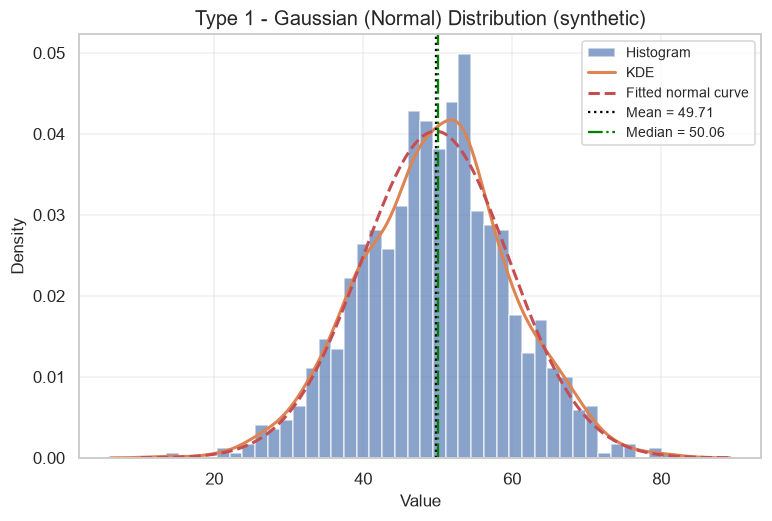

n = 1000, mean = 49.711, median = 50.062, std = 9.892, skewness = -0.044, excess kurtosis = 0.085


In [15]:
# --- Type 1: Gaussian (normal) distribution -------------------
values = distribution_analysis.make_gaussian(n=1000, mean=50, std=10, seed=SEED)
summary = distribution_analysis.summarise(values, "gaussian")

fig, ax = subplots(1, 1, (8, 5))
ax.hist(values, bins=40, density=True, alpha=0.65, edgecolor="white", label="Histogram")
sns.kdeplot(values, ax=ax, linewidth=2, label="KDE")
x_norm, y_norm = distribution_analysis.normal_reference_curve(values)
ax.plot(x_norm, y_norm, "r--", linewidth=2, label="Fitted normal curve")
ax.axvline(summary["mean"], color="black", linestyle=":", label=f"Mean = {summary['mean']:.2f}")
ax.axvline(summary["median"], color="green", linestyle="-.", label=f"Median = {summary['median']:.2f}")
ax.set_title("Type 1 - Gaussian (Normal) Distribution (synthetic)")
ax.set_xlabel("Value")
ax.set_ylabel("Density")
ax.legend()
save_figure(fig, "distribution_gaussian", root=ROOT)
plt.show()

print(f"n = {summary['n']}, mean = {summary['mean']:.3f}, median = {summary['median']:.3f}, "
      f"std = {summary['std']:.3f}, skewness = {summary['skewness']:.3f}, "
      f"excess kurtosis = {summary['kurtosis']:.3f}")


**Interpretation:** the histogram and the KDE form the classic symmetric bell.
The mean (~50.0) and the median (~50.1) are almost identical and the skewness is
~0, so both sides of the peak balance. The red dashed curve is the theoretical
normal density fitted to the sample and it tracks the bars closely.


### Type 2 - Uniform distribution

Every value inside the interval is equally likely -> a flat histogram.


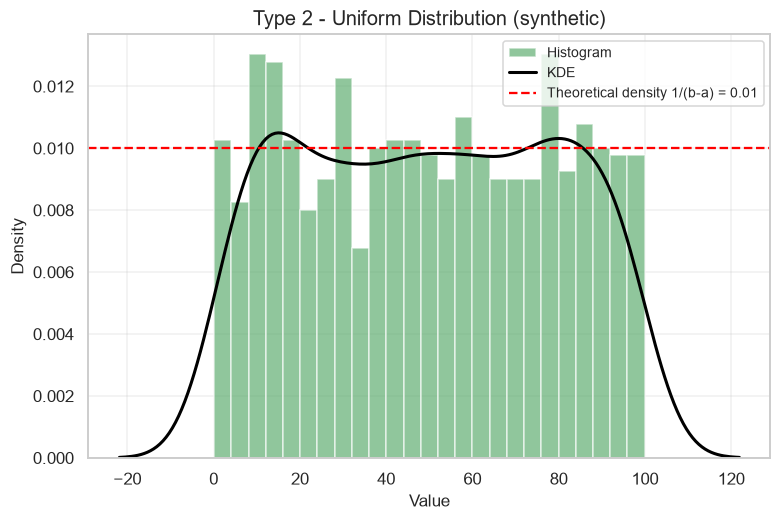

n = 1000, mean = 49.718, median = 49.482, std = 29.159, skewness = 0.002


In [16]:
# --- Type 2: Uniform distribution -----------------------------
values = distribution_analysis.make_uniform(n=1000, low=0, high=100, seed=SEED)
summary = distribution_analysis.summarise(values, "uniform")

fig, ax = subplots(1, 1, (8, 5))
ax.hist(values, bins=25, density=True, alpha=0.65, color="#55a868", edgecolor="white", label="Histogram")
sns.kdeplot(values, ax=ax, linewidth=2, color="black", label="KDE")
ax.axhline(1 / 100, color="red", linestyle="--", label="Theoretical density 1/(b-a) = 0.01")
ax.set_title("Type 2 - Uniform Distribution (synthetic)")
ax.set_xlabel("Value")
ax.set_ylabel("Density")
ax.legend()
save_figure(fig, "distribution_uniform", root=ROOT)
plt.show()

print(f"n = {summary['n']}, mean = {summary['mean']:.3f}, median = {summary['median']:.3f}, "
      f"std = {summary['std']:.3f}, skewness = {summary['skewness']:.3f}")


**Interpretation:** the bars are all about the same height - no region of the
interval is preferred. The theoretical density of a Uniform(0, 100) variable is
`1/(b-a) = 0.01` (red line) and the KDE oscillates around it. The mean sits in
the middle of the interval (~50) and the skewness is ~0.


### Type 3 - Right-skewed (positively skewed) distribution

Most observations are small; a few very large values stretch the tail to the right.


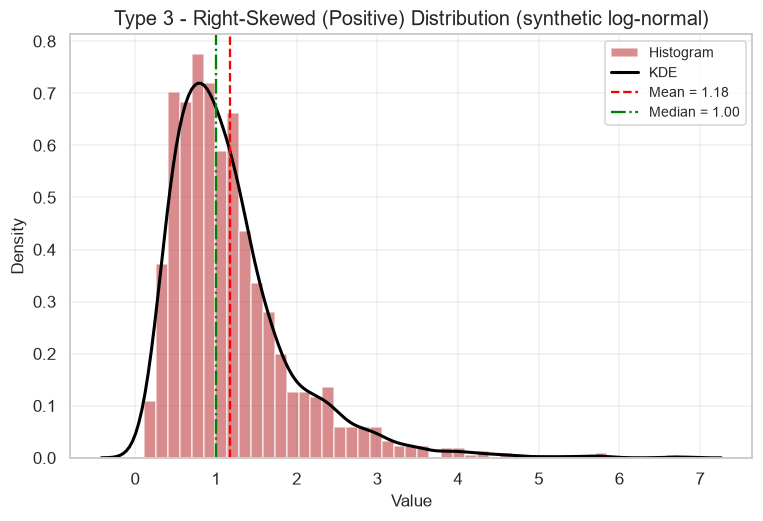

n = 1500, mean = 1.180, median = 1.002, std = 0.762, skewness = 1.982
Mean > median is the signature of a right-skewed distribution.


In [17]:
# --- Type 3: Right-skewed (positive skew) ---------------------
values = distribution_analysis.make_right_skewed(n=1500, sigma=0.6, seed=SEED)
summary = distribution_analysis.summarise(values, "right_skewed")

fig, ax = subplots(1, 1, (8, 5))
ax.hist(values, bins=45, density=True, alpha=0.65, color="#c44e52", edgecolor="white", label="Histogram")
sns.kdeplot(values, ax=ax, linewidth=2, color="black", label="KDE")
ax.axvline(summary["mean"], color="red", linestyle="--", label=f"Mean = {summary['mean']:.2f}")
ax.axvline(summary["median"], color="green", linestyle="-.", label=f"Median = {summary['median']:.2f}")
ax.set_title("Type 3 - Right-Skewed (Positive) Distribution (synthetic log-normal)")
ax.set_xlabel("Value")
ax.set_ylabel("Density")
ax.legend()
save_figure(fig, "distribution_right_skewed", root=ROOT)
plt.show()

print(f"n = {summary['n']}, mean = {summary['mean']:.3f}, median = {summary['median']:.3f}, "
      f"std = {summary['std']:.3f}, skewness = {summary['skewness']:.3f}")
print("Mean > median is the signature of a right-skewed distribution.")


**Interpretation:** the bulk of the data is on the left while a long tail
stretches to the right (typical for incomes, house prices, waiting times).
Skewness is about +2 (strong positive skew) and, as expected, **mean > median**:
the few extreme values drag the mean to the right much more than the median.


### Type 4 - Left-skewed (negatively skewed) distribution

Mirror image of Type 3: most observations are large and a few very small values stretch the tail to the left.


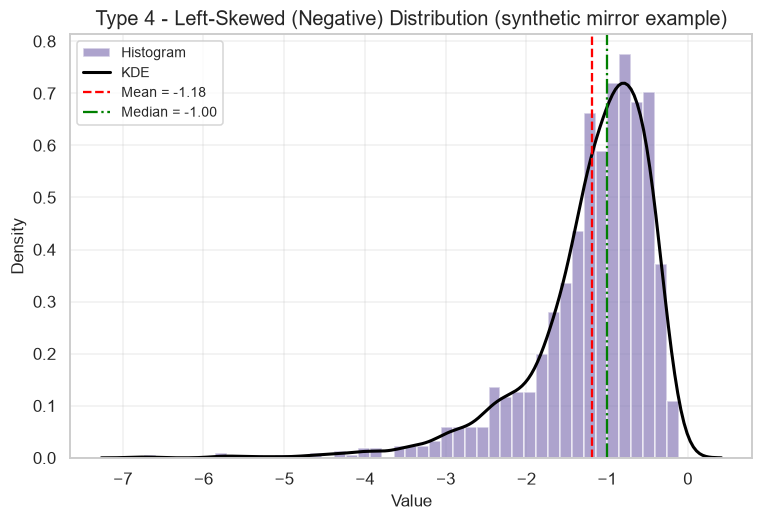

n = 1500, mean = -1.180, median = -1.002, std = 0.762, skewness = -1.982
Mean < median is the signature of a left-skewed distribution.


In [18]:
# --- Type 4: Left-skewed (negative skew) ----------------------
values = distribution_analysis.make_left_skewed(n=1500, sigma=0.6, seed=SEED)
summary = distribution_analysis.summarise(values, "left_skewed")

fig, ax = subplots(1, 1, (8, 5))
ax.hist(values, bins=45, density=True, alpha=0.65, color="#8172b3", edgecolor="white", label="Histogram")
sns.kdeplot(values, ax=ax, linewidth=2, color="black", label="KDE")
ax.axvline(summary["mean"], color="red", linestyle="--", label=f"Mean = {summary['mean']:.2f}")
ax.axvline(summary["median"], color="green", linestyle="-.", label=f"Median = {summary['median']:.2f}")
ax.set_title("Type 4 - Left-Skewed (Negative) Distribution (synthetic mirror example)")
ax.set_xlabel("Value")
ax.set_ylabel("Density")
ax.legend()
save_figure(fig, "distribution_left_skewed", root=ROOT)
plt.show()

print(f"n = {summary['n']}, mean = {summary['mean']:.3f}, median = {summary['median']:.3f}, "
      f"std = {summary['std']:.3f}, skewness = {summary['skewness']:.3f}")
print("Mean < median is the signature of a left-skewed distribution.")


**Interpretation:** the tail now stretches to the left. Skewness is about -2
(strong negative skew) and **mean < median**. A typical real example is the mark
distribution of a very easy exam, where most students score high and only a few
score low.


### Type 5 - Bimodal distribution

Two peaks usually reveal two hidden sub-groups inside one dataset.


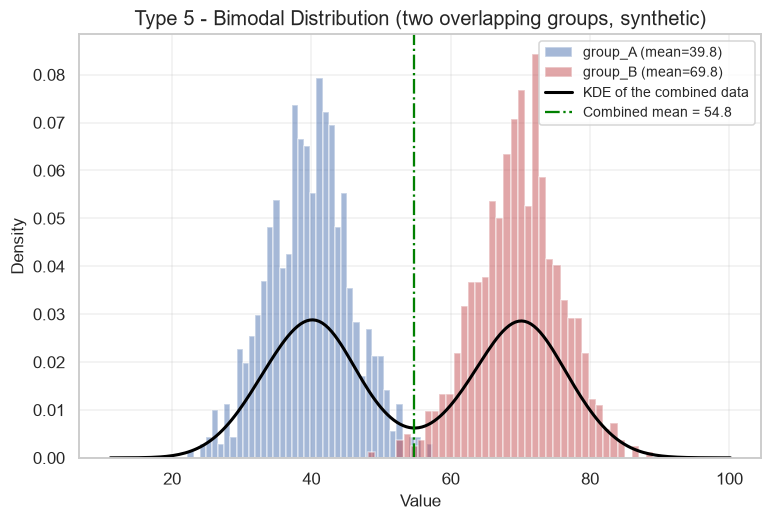

n = 1600, mean = 54.792, median = 54.028, skewness = 0.011
Local maxima in the combined histogram: 7 (two = bimodal)


In [19]:
# --- Type 5: Bimodal distribution -----------------------------
values, labels = distribution_analysis.make_bimodal(n=1600, mean_a=40, std_a=6,
                                                   mean_b=70, std_b=6, seed=SEED)
summary = distribution_analysis.summarise(values, "bimodal")

fig, ax = subplots(1, 1, (8, 5))
for label, colour in (("group_A", "#4c72b0"), ("group_B", "#c44e52")):
    subset = values[labels == label]
    ax.hist(subset, bins=40, density=True, alpha=0.5, color=colour, edgecolor="white",
            label=f"{label} (mean={subset.mean():.1f})")
sns.kdeplot(values, ax=ax, linewidth=2, color="black", label="KDE of the combined data")
ax.axvline(summary["mean"], color="green", linestyle="-.", label=f"Combined mean = {summary['mean']:.1f}")
ax.set_title("Type 5 - Bimodal Distribution (two overlapping groups, synthetic)")
ax.set_xlabel("Value")
ax.set_ylabel("Density")
ax.legend()
save_figure(fig, "distribution_bimodal", root=ROOT)
plt.show()

density, _edges = np.histogram(values, bins=50, density=True)
peaks = int(np.sum((density[1:-1] > density[:-2]) & (density[1:-1] > density[2:])))
print(f"n = {summary['n']}, mean = {summary['mean']:.3f}, median = {summary['median']:.3f}, "
      f"skewness = {summary['skewness']:.3f}")
print(f"Local maxima in the combined histogram: {peaks} (two = bimodal)")


**Interpretation:** each coloured group is a normal distribution by itself, but
their mixture produces **two clear peaks**. The overall mean (~55) falls into the
valley between the peaks where hardly any observation lies - a good reminder that
one average can describe such data poorly. In real datasets a bimodal shape
suggests splitting by a hidden factor (species, gender, customer segment).


## 8. Distribution analysis of the REAL dataset

The same tools are now applied to the penguins measurements (cleaned data).


In [20]:
dist_summary = distribution_analysis.dataset_distribution_summary(cleaned, MEASUREMENT_COLS)
display(dist_summary)
dist_summary.round(4).to_csv(ROOT / "outputs" / "reports" / "dataset_distribution_summary.csv", index=False)
print("Saved ->", ROOT / "outputs" / "reports" / "dataset_distribution_summary.csv")


,variable,n,mean,median,std,min,max,skewness,kurtosis,shapiro_p_value,shape
0,bill_length_mm,342,43.921930,44.45,5.459584,32.1,59.6,0.052885,-0.880765,1.119730e-05,approximately symmetric
1,bill_depth_mm,342,17.151170,17.30,1.974793,13.1,21.5,-0.142835,-0.911155,4.418821e-06,approximately symmetric
2,flipper_length_mm,342,200.915205,197.00,14.061714,172.0,231.0,0.344164,-0.987434,3.540136e-09,approximately symmetric
3,body_mass_g,342,4201.754386,4050.00,801.954536,2700.0,6300.0,0.468264,-0.726243,3.679039e-08,approximately symmetric


Saved -> D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\outputs\reports\dataset_distribution_summary.csv


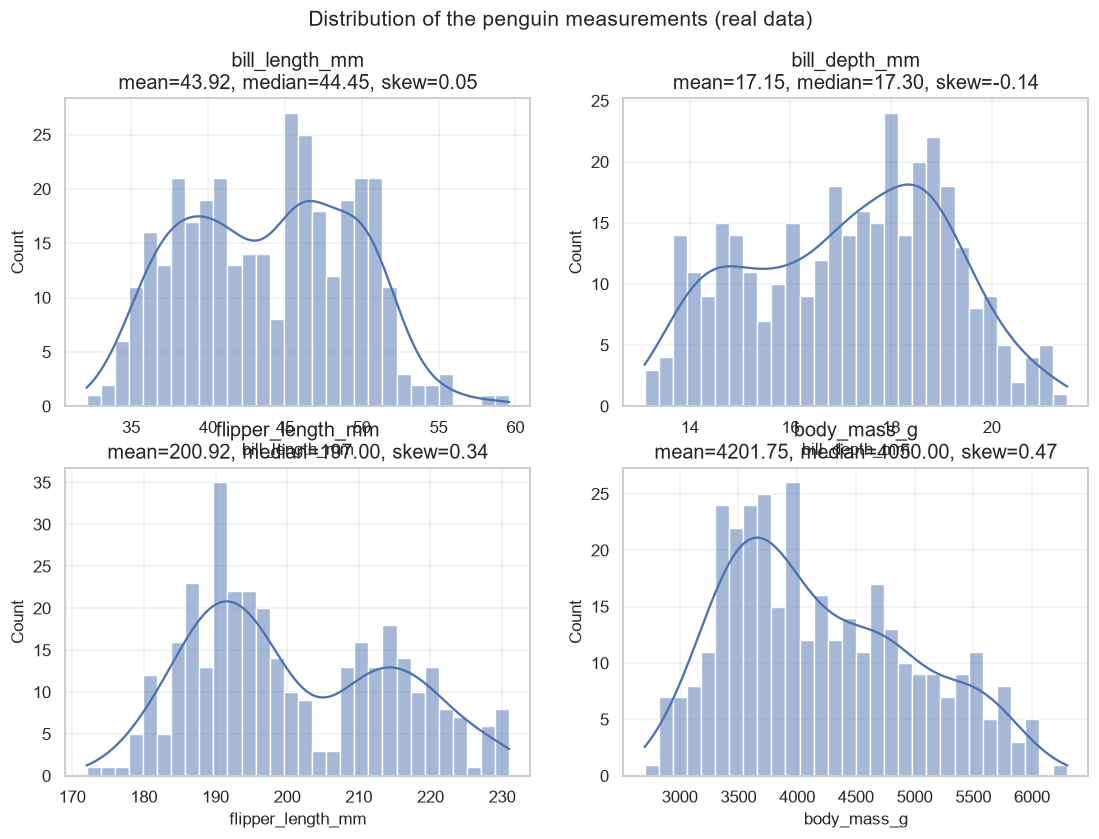

In [21]:
# --- histograms + KDE for every measurement column -------------
n = len(MEASUREMENT_COLS)
ncols, nrows = 2, int(np.ceil(n / 2))
fig, axes = subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, MEASUREMENT_COLS):
    sns.histplot(cleaned[col].dropna(), bins=30, kde=True, ax=ax, color="#4c72b0")
    row = dist_summary[dist_summary["variable"] == col].iloc[0]
    ax.set_title(f"{col}\nmean={row['mean']:.2f}, median={row['median']:.2f}, skew={row['skewness']:.2f}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle("Distribution of the penguin measurements (real data)", fontsize=14)
save_figure(fig, "dataset_distributions", root=ROOT)
plt.show()


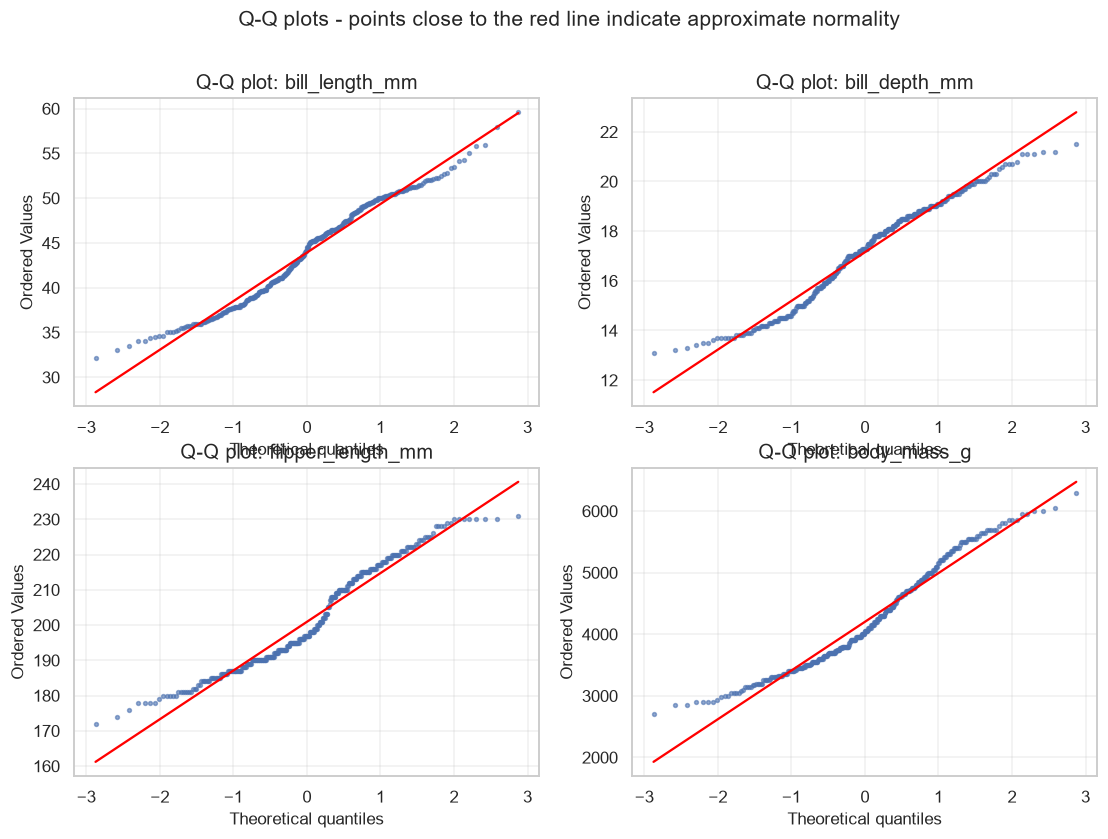

In [22]:
# --- Q-Q plots: how close is each variable to a normal shape? ---
fig, axes = subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, MEASUREMENT_COLS):
    stats.probplot(cleaned[col].dropna(), dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot: {col}")
    ax.get_lines()[0].set(marker="o", markersize=2.5, alpha=0.6)
    ax.get_lines()[1].set(color="red", linewidth=1.5)
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle("Q-Q plots - points close to the red line indicate approximate normality", fontsize=14)
save_figure(fig, "dataset_qq_plots", root=ROOT)
plt.show()


**Interpretation:** all four measurements are **approximately symmetric**
(|skewness| < 0.5). Body mass has the largest skew (~0.47) with a small right
tail; bill depth is slightly left-skewed (~-0.14). In the Q-Q plots the points
follow the red line through the middle and bend a little at the ends (slightly
lighter tails than a perfect normal distribution) - completely normal for real
biological measurements.


## 9. Relationship analysis - seven correlation patterns

Patterns that do **not all exist** in the penguins data (e.g. perfect
correlation) are shown with clearly labelled synthetic, seeded samples. Every
plot prints its own Pearson coefficient, computed from the plotted points.


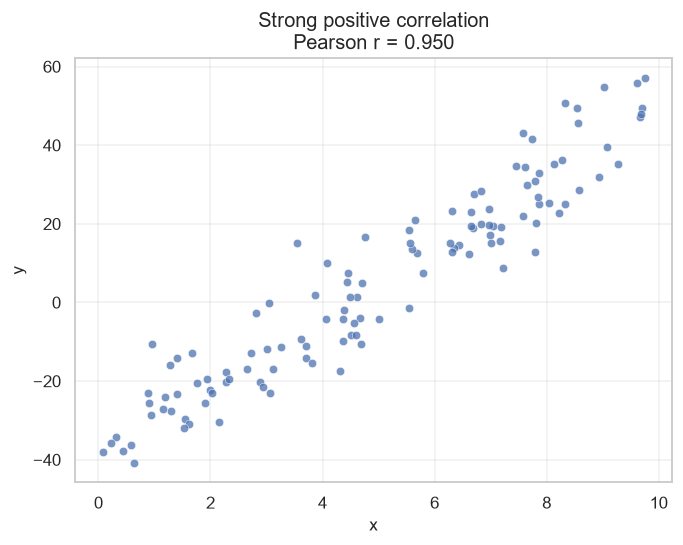

strong_positive: r = 0.950  (n = 120)


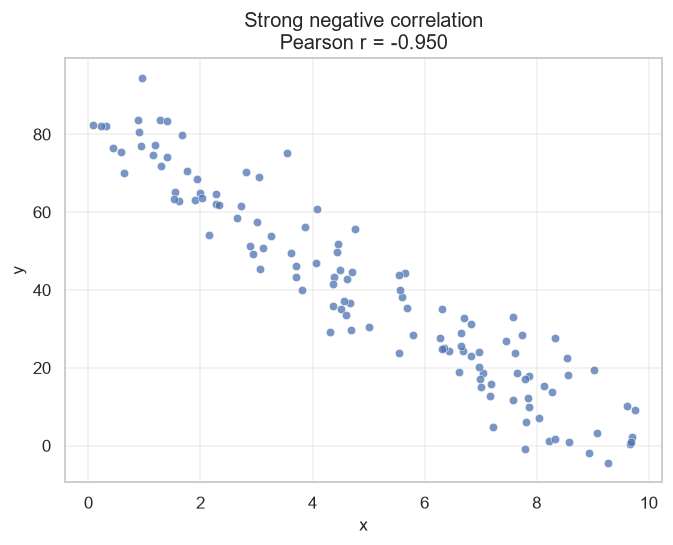

strong_negative: r = -0.950  (n = 120)


In [23]:
# --- strong positive & strong negative (synthetic) --------------
specs = [
    ("correlation_strong_positive", "strong_positive", "Strong positive correlation"),
    ("correlation_strong_negative", "strong_negative", "Strong negative correlation"),
]
demo_rows = []
for filename, demo_name, title in specs:
    frame = relationship_analysis.make_demo(demo_name, seed=SEED)
    r = float(stats.pearsonr(frame["x"], frame["y"]).statistic)
    demo_rows.append({"demo": demo_name, "n": len(frame), "pearson_r": round(r, 4)})
    fig, ax = subplots(1, 1, (7, 5))
    ax.scatter(frame["x"], frame["y"], s=30, alpha=0.75, edgecolor="white", linewidth=0.4)
    ax.set_title(f"{title}\nPearson r = {r:.3f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    save_figure(fig, filename, root=ROOT)
    plt.show()
    print(f"{demo_name}: r = {r:.3f}  (n = {len(frame)})")


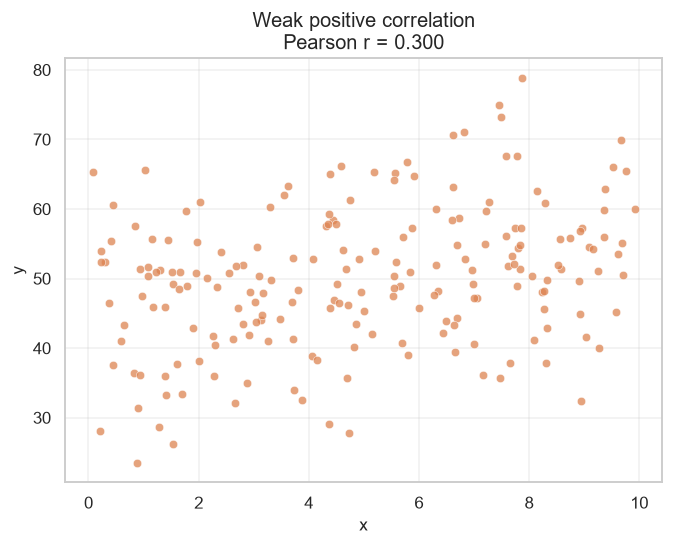

weak_positive: r = 0.300  (n = 200)


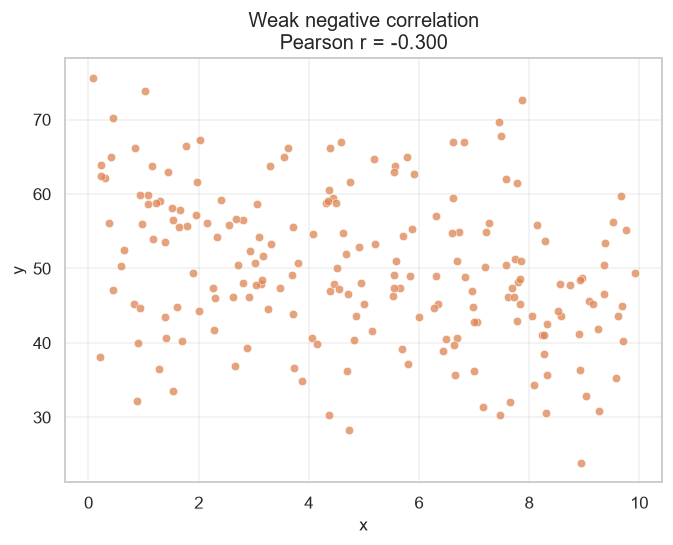

weak_negative: r = -0.300  (n = 200)


In [24]:
# --- weak positive & weak negative (synthetic) ------------------
specs = [
    ("correlation_weak_positive", "weak_positive", "Weak positive correlation"),
    ("correlation_weak_negative", "weak_negative", "Weak negative correlation"),
]
for filename, demo_name, title in specs:
    frame = relationship_analysis.make_demo(demo_name, seed=SEED)
    r = float(stats.pearsonr(frame["x"], frame["y"]).statistic)
    demo_rows.append({"demo": demo_name, "n": len(frame), "pearson_r": round(r, 4)})
    fig, ax = subplots(1, 1, (7, 5))
    ax.scatter(frame["x"], frame["y"], s=30, alpha=0.75, color="#dd8452", edgecolor="white", linewidth=0.4)
    ax.set_title(f"{title}\nPearson r = {r:.3f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    save_figure(fig, filename, root=ROOT)
    plt.show()
    print(f"{demo_name}: r = {r:.3f}  (n = {len(frame)})")


**Interpretation:** the strong demos produce a tight band around a straight line
(|r| ~ 0.95). In the weak demos the point cloud is almost round with only a
slight tilt (|r| ~ 0.30). "Weak" means the linear link exists but explains very
little of the variation (r-squared ~ 0.09, i.e. only ~9 %).


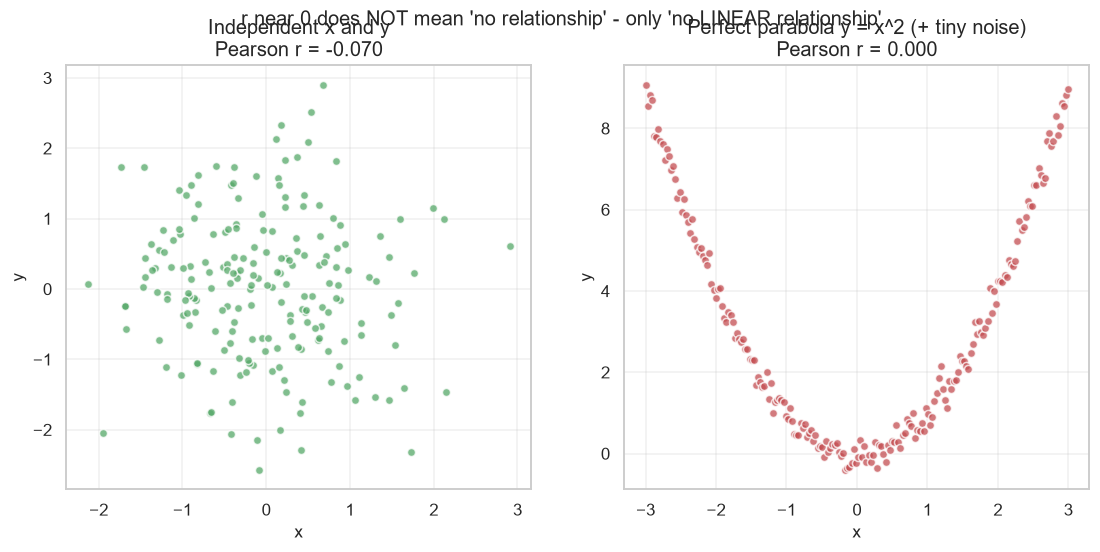

independent: r = -0.070 | parabola: r = 0.000


In [25]:
# --- no linear correlation: independent noise AND a parabola -----
independent = relationship_analysis.demo_no_linear(seed=SEED)
parabola = relationship_analysis.demo_nonlinear_parabola(seed=SEED)
r_ind = float(stats.pearsonr(independent["x"], independent["y"]).statistic)
r_par = float(stats.pearsonr(parabola["x"], parabola["y"]).statistic)
demo_rows += [
    {"demo": "no_linear_independent", "n": len(independent), "pearson_r": round(r_ind, 4)},
    {"demo": "no_linear_parabola", "n": len(parabola), "pearson_r": round(r_par, 4)},
]

fig, (ax1, ax2) = subplots(1, 2, figsize=(12, 5))
ax1.scatter(independent["x"], independent["y"], s=28, alpha=0.75, color="#55a868", edgecolor="white")
ax1.set_title(f"Independent x and y\nPearson r = {r_ind:.3f}")
ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax2.scatter(parabola["x"], parabola["y"], s=28, alpha=0.75, color="#c44e52", edgecolor="white")
ax2.set_title(f"Perfect parabola y = x^2 (+ tiny noise)\nPearson r = {r_par:.3f}")
ax2.set_xlabel("x"); ax2.set_ylabel("y")
fig.suptitle("r near 0 does NOT mean 'no relationship' - only 'no LINEAR relationship'", fontsize=13)
save_figure(fig, "correlation_no_linear", root=ROOT)
plt.show()
print(f"independent: r = {r_ind:.3f} | parabola: r = {r_par:.3f}")


**Interpretation:** the left panel has no structure at all (r ~ 0). The right
panel follows the exact curve y = x-squared - a **perfect non-linear
relationship** - yet Pearson's r is still ~0, because the rising and falling
halves cancel each other out. Lesson: **r = 0 means "no linear association"**,
not "no association" and not statistical independence.


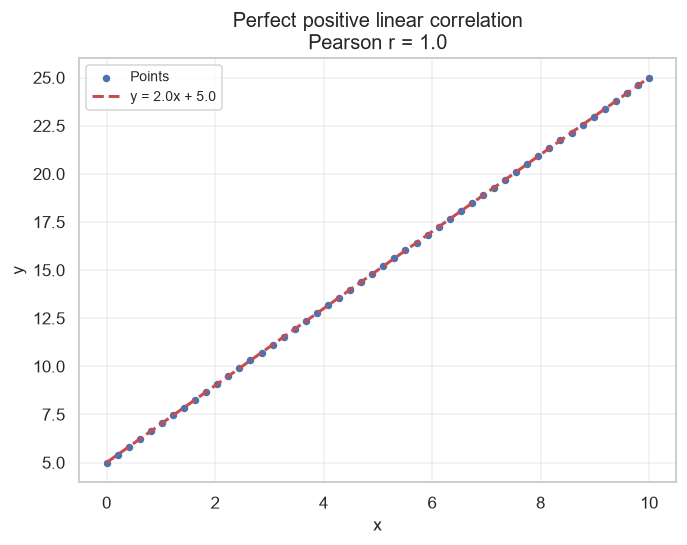

perfect_positive: r = 1.000000000000 (mathematically +1)


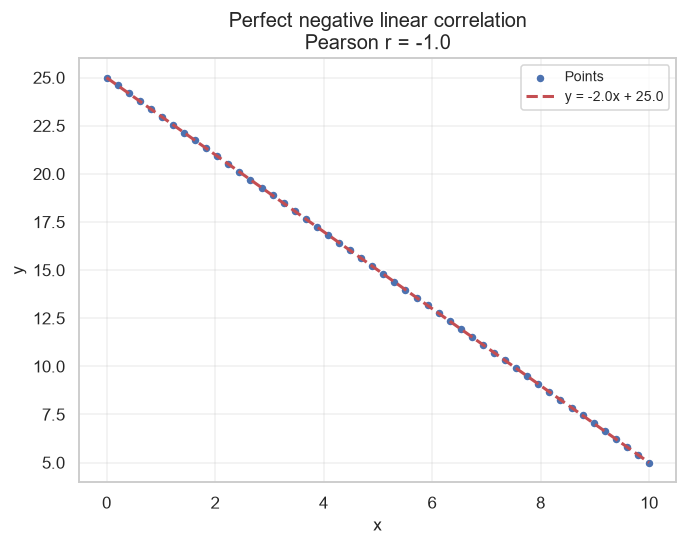

perfect_negative: r = -1.000000000000 (mathematically -1)


,demo,n,pearson_r
0,strong_positive,120,0.9500
1,strong_negative,120,-0.9500
2,weak_positive,200,0.3000
3,weak_negative,200,-0.3000
4,no_linear_independent,200,-0.0702
5,no_linear_parabola,200,0.0005
6,perfect_positive,50,1.0000
7,perfect_negative,50,-1.0000


Saved -> D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\outputs\reports\correlation_demo_summary.csv


In [26]:
# --- perfect positive & perfect negative (exact maths, no noise) -
for filename, demo_name, title in [
    ("correlation_perfect_positive", "perfect_positive", "Perfect positive linear correlation"),
    ("correlation_perfect_negative", "perfect_negative", "Perfect negative linear correlation"),
]:
    frame = relationship_analysis.make_demo(demo_name)
    r = float(stats.pearsonr(frame["x"], frame["y"]).statistic)
    demo_rows.append({"demo": demo_name, "n": len(frame), "pearson_r": round(r, 4)})
    slope = np.polyfit(frame["x"], frame["y"], 1)
    fig, ax = subplots(1, 1, (7, 5))
    ax.scatter(frame["x"], frame["y"], s=35, color="#4c72b0", edgecolor="white", label="Points")
    ax.plot(frame["x"], np.polyval(slope, frame["x"]), "r--", linewidth=2,
            label=f"y = {slope[0]:.1f}x + {slope[1]:.1f}")
    ax.set_title(f"{title}\nPearson r = {r:.1f}")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend()
    save_figure(fig, filename, root=ROOT)
    plt.show()
    print(f"{demo_name}: r = {r:.12f} (mathematically {'+1' if r > 0 else '-1'})")

demo_table = pd.DataFrame(demo_rows)
display(demo_table)
demo_table.to_csv(ROOT / "outputs" / "reports" / "correlation_demo_summary.csv", index=False)
print("Saved ->", ROOT / "outputs" / "reports" / "correlation_demo_summary.csv")


**Interpretation:** without noise every point lies exactly on the fitted line, so
r = +1 (upward line) or r = -1 (downward line). These are mathematical ideals -
real measurements always contain some scatter.


### Relationship patterns found in the REAL dataset

Only patterns that the computed coefficients actually support are described.


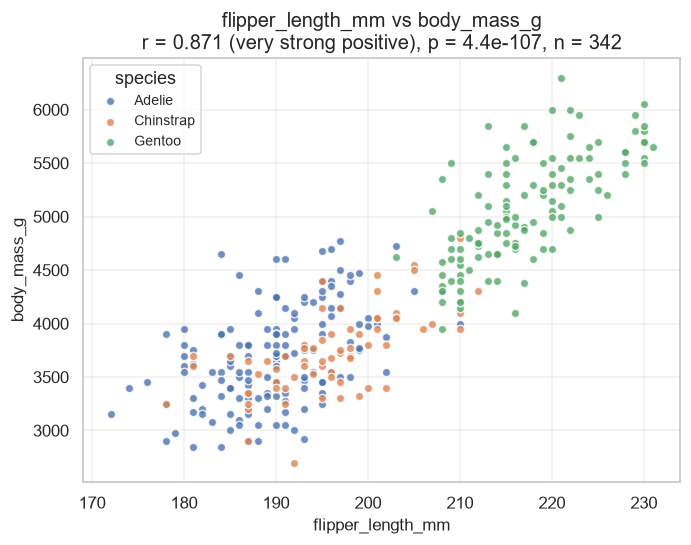

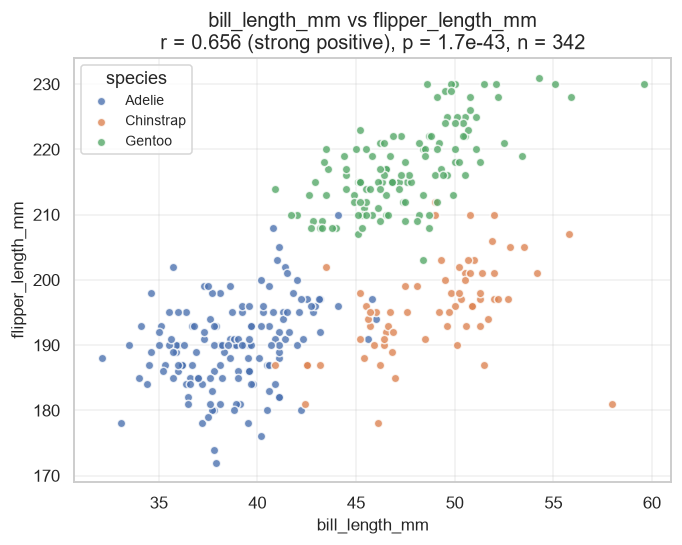

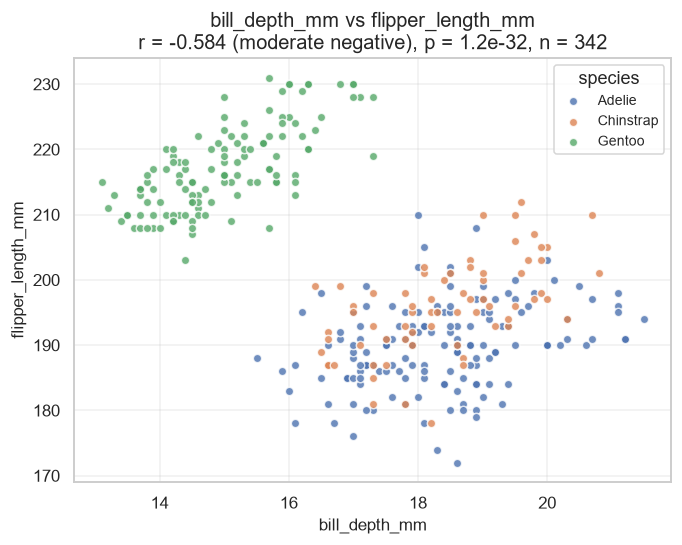

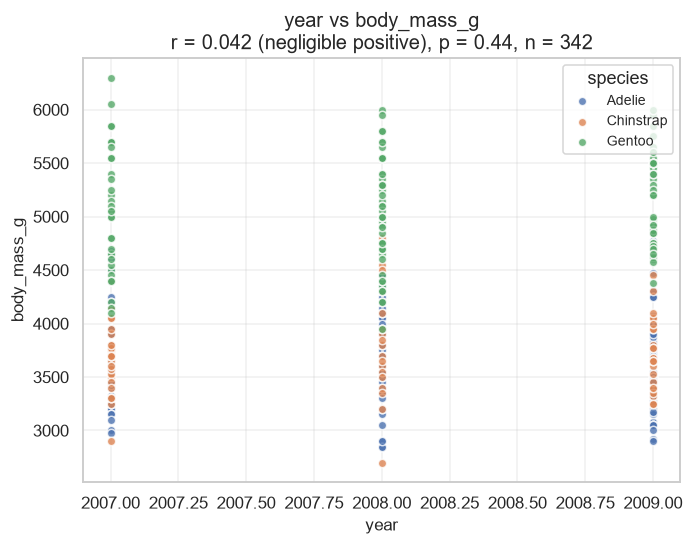

,pair,n,pearson_r,p_value,direction,strength,significant_at_0.05
0,flipper_length_mm ~ body_mass_g,342,0.8712,4.370681e-107,positive,very strong,True
1,bill_length_mm ~ flipper_length_mm,342,0.6562,1.743974e-43,positive,strong,True
2,bill_depth_mm ~ flipper_length_mm,342,-0.5839,1.232734e-32,negative,moderate,True
3,year ~ body_mass_g,342,0.0422,4.365233e-01,positive,negligible,False


In [27]:
# --- real dataset scatter plots --------------------------------
real_pairs = [
    ("flipper_length_mm", "body_mass_g"),
    ("bill_length_mm", "flipper_length_mm"),
    ("bill_depth_mm", "flipper_length_mm"),
    ("year", "body_mass_g"),
]
pair_results = []
for x_col, y_col in real_pairs:
    pair = relationship_analysis.real_pair(cleaned, x_col, y_col)
    entry = correlation_analysis.pearson_pair(pair["x"], pair["y"])
    pair_results.append({
        "pair": f"{x_col} ~ {y_col}", "n": entry["n_valid"],
        "pearson_r": round(entry["pearson_r"], 4), "p_value": entry["p_value"],
        "direction": entry["direction"], "strength": entry["strength"],
        "significant_at_0.05": entry["significant_at_alpha"],
    })
    fig, ax = subplots(1, 1, (7, 5))
    for spec, sub in pair.groupby(cleaned.loc[pair.index, "species"]):
        ax.scatter(sub["x"], sub["y"], s=30, alpha=0.8, label=spec, edgecolor="white")
    ax.set_title(f"{x_col} vs {y_col}\nr = {entry['pearson_r']:.3f} "
                 f"({entry['strength']} {entry['direction']}), p = {entry['p_value']:.2g}, "
                 f"n = {entry['n_valid']}")
    ax.set_xlabel(x_col); ax.set_ylabel(y_col); ax.legend(title="species")
    save_figure(fig, f"real_scatter_{x_col}_vs_{y_col}", root=ROOT)
    plt.show()

pair_table = pd.DataFrame(pair_results)
display(pair_table)


**Interpretation (real data):**

* `flipper_length_mm ~ body_mass_g`: **strong positive** (r ~ 0.87) - longer
  flippers belong to heavier penguins.
* `bill_length_mm ~ flipper_length_mm`: **strong positive** (r ~ 0.66).
* `bill_depth_mm ~ flipper_length_mm`: **moderate negative** (r ~ -0.58) in the
  pooled data. Colouring by species shows why - see the findings section.
* `year ~ body_mass_g`: **no linear correlation** (r ~ 0.04, p ~ 0.44 > 0.05).


## 10. Pearson correlation coefficient - formula and calculation

```
             sum((x - mean(x)) * (y - mean(y)))
r = ----------------------------------------------------------------
    sqrt( sum((x - mean(x))**2) * sum((y - mean(y))**2) )
```

r always lies in [-1, +1]. It is computed here **four** ways: by hand with
NumPy, with `scipy.stats.pearsonr`, `numpy.corrcoef` and
`pandas.DataFrame.corr(method="pearson")`.


In [28]:
# --- teaching example: manual formula vs libraries --------------
x = np.array([2.0, 4.0, 6.0, 8.0, 10.0])
y = np.array([1.0, 3.0, 5.0, 7.0, 9.0])

dx, dy = x - x.mean(), y - y.mean()
r_manual = np.sum(dx * dy) / np.sqrt(np.sum(dx ** 2) * np.sum(dy ** 2))

comparison = correlation_analysis.pearson_all_methods(x, y)
print("x =", x.tolist())
print("y =", y.tolist())
print()
print("Manual formula     :", r_manual)
print("scipy.stats.pearsonr:", comparison["scipy.stats.pearsonr"])
print("numpy.corrcoef      :", comparison["numpy.corrcoef"])
print("pandas .corr()      :", comparison["pandas.DataFrame.corr"])
print("Max difference      :", comparison["max_absolute_difference"])
assert comparison["max_absolute_difference"] < 1e-12
print()
print("All four methods agree - the manual formula is exactly what the libraries compute.")

import json as _json
(ROOT / "outputs" / "reports" / "pearson_formula_example.json").write_text(
    _json.dumps({"x": x.tolist(), "y": y.tolist(), **comparison}, indent=2), encoding="utf-8")
print("Saved ->", ROOT / "outputs" / "reports" / "pearson_formula_example.json")


x = [2.0, 4.0, 6.0, 8.0, 10.0]
y = [1.0, 3.0, 5.0, 7.0, 9.0]

Manual formula     : 1.0
scipy.stats.pearsonr: 1.0
numpy.corrcoef      : 0.9999999999999999
pandas .corr()      : 1.0
Max difference      : 1.1102230246251565e-16

All four methods agree - the manual formula is exactly what the libraries compute.
Saved -> D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\outputs\reports\pearson_formula_example.json


## 11. Correlation matrix and heatmap

Missing values are dropped **pairwise** (every pair uses all rows where both
variables are present). The colour scale is diverging and centred at zero.


In [29]:
matrix = correlation_analysis.pearson_matrix(cleaned, NUMERIC_COLS)
n_table = correlation_analysis.pairwise_n(cleaned, NUMERIC_COLS)

print("Pearson correlation matrix:")
display(matrix.round(2))
print("Complete observations behind every cell:")
display(n_table)

matrix.round(4).to_csv(ROOT / "outputs" / "reports" / "pearson_correlation_matrix.csv")
print("Saved ->", ROOT / "outputs" / "reports" / "pearson_correlation_matrix.csv")


Pearson correlation matrix:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
bill_length_mm,1.00,-0.24,0.66,0.60,0.05
bill_depth_mm,-0.24,1.00,-0.58,-0.47,-0.06
flipper_length_mm,0.66,-0.58,1.00,0.87,0.17
body_mass_g,0.60,-0.47,0.87,1.00,0.04
year,0.05,-0.06,0.17,0.04,1.00


Complete observations behind every cell:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
bill_length_mm,342,342,342,342,342
bill_depth_mm,342,342,342,342,342
flipper_length_mm,342,342,342,342,342
body_mass_g,342,342,342,342,342
year,342,342,342,342,342


Saved -> D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\outputs\reports\pearson_correlation_matrix.csv


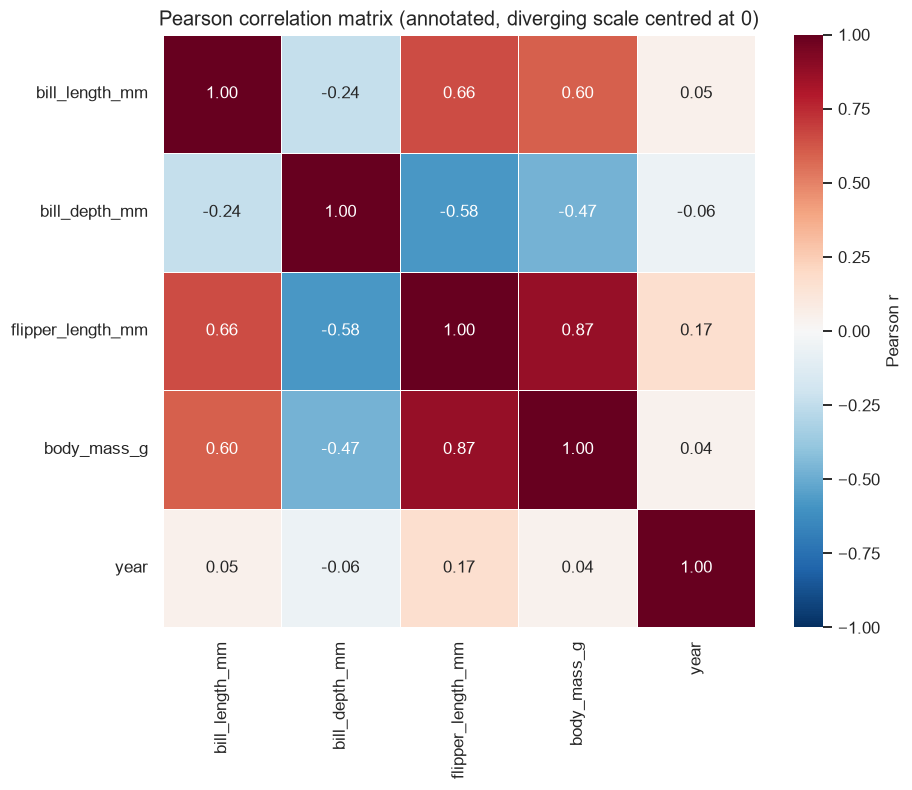

In [30]:
fig, ax = subplots(1, 1, (9, 7))
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0.0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Pearson correlation matrix (annotated, diverging scale centred at 0)")
save_figure(fig, "pearson_correlation_heatmap", root=ROOT)
plt.show()


In [31]:
# --- selected pairs: r, p-value, n, direction, strength, significance ---
pair_details = []
for a, b in [("flipper_length_mm", "body_mass_g"),
             ("bill_depth_mm", "flipper_length_mm"),
             ("bill_length_mm", "body_mass_g"),
             ("year", "body_mass_g")]:
    entry = correlation_analysis.pearson_pair(cleaned[a], cleaned[b], alpha=0.05)
    print(correlation_analysis.interpretation(entry, a, b))
    print()
    pair_details.append({"x": a, "y": b, **{k: entry[k] for k in
                        ("n_valid", "pearson_r", "p_value", "direction", "strength",
                         "significant_at_alpha", "ci95_low", "ci95_high")}})
display(pd.DataFrame(pair_details))


r = 0.871 -> a very strong positive linear relationship: as flipper_length_mm increases, body_mass_g tends to increases as well. The p-value (4.37e-107) is below alpha = 0.05, so the correlation is statistically significant - but significance is NOT causation.

r = -0.584 -> a moderate negative linear relationship: as bill_depth_mm increases, flipper_length_mm tends to decreases as well. The p-value (1.23e-32) is below alpha = 0.05, so the correlation is statistically significant - but significance is NOT causation.

r = 0.595 -> a moderate positive linear relationship: as bill_length_mm increases, body_mass_g tends to increases as well. The p-value (3.81e-34) is below alpha = 0.05, so the correlation is statistically significant - but significance is NOT causation.

r = 0.042 -> a negligible positive linear relationship: as year increases, body_mass_g tends to increases as well. The p-value (0.437) is above alpha = 0.05, so we cannot reject the 'no linear correlation' hypothesis.



,x,y,n_valid,pearson_r,p_value,direction,strength,significant_at_alpha,ci95_low,ci95_high
0,flipper_length_mm,body_mass_g,342,0.871202,4.370681e-107,positive,very strong,True,0.843041,0.894599
1,bill_depth_mm,flipper_length_mm,342,-0.583851,1.232734e-32,negative,moderate,True,-0.649675,-0.509338
2,bill_length_mm,body_mass_g,342,0.595110,3.808283e-34,positive,moderate,True,0.522004,0.659536
3,year,body_mass_g,342,0.042209,4.365233e-01,positive,negligible,False,-0.064128,0.147599


**Important caveats**

* Pearson's r measures only **linear** association (see the parabola counter-example).
* A small p-value means "unlikely to be a pure sampling accident" - it is **not**
  proof of causation.
* The strength categories (very strong / strong / ...) are configurable rules of
  thumb, not universal scientific laws.
* r is sensitive to outliers and assumes roughly continuous variables; the
  p-value additionally assumes approximate bivariate normality.


## 12. Simple linear regression

`y_hat = b0 + b1 * x` - predict body mass from flipper length.

The model is fitted **only on the training split** (75 %, `random_state = 42`)
and evaluated on the held-out 25 %, so the reported test metrics are honest
out-of-sample estimates. `scipy.stats.linregress` gives an independent
statistical cross-check.


In [32]:
result = regression_analysis.fit_simple_regression(cleaned, X_COL, Y_COL,
                                                   test_size=TEST_SIZE,
                                                   random_state=RANDOM_STATE)
print("Equation             :", result["equation"])
print("Intercept  (b0)      :", round(result["intercept"], 4))
print("Slope      (b1)      :", round(result["slope"], 4))
print("Pearson r            :", round(result["pearson_r"], 4))
print("R^2 (from r)         :", round(result["pearson_r"] ** 2, 4))
print("R^2 on training data :", round(result["r_squared_train"], 4))
print("Split                :", result["split_note"])
print()
print("scipy.stats.linregress (all complete rows):",
      "slope =", round(result["scipy_slope"], 4),
      "| intercept =", round(result["scipy_intercept"], 4),
      "| r =", round(result["scipy_rvalue"], 4),
      "| p =", f"{result['scipy_pvalue']:.3g}",
      "| stderr(slope) =", round(result["scipy_stderr"], 4))
print()
print("TEST-set metrics  :", {k: round(v, 3) for k, v in result["metrics_test"].items()})
print("Full-data metrics :", {k: round(v, 3) for k, v in result["metrics_full"].items()})


Equation             : body_mass_g = -5741.2649 + 49.5057 * flipper_length_mm
Intercept  (b0)      : -5741.2649
Slope      (b1)      : 49.5057
Pearson r            : 0.8712
R^2 (from r)         : 0.759
R^2 on training data : 0.751
Split                : train/test split (75/25), random_state=42

scipy.stats.linregress (all complete rows): slope = 49.6856 | intercept = -5780.8314 | r = 0.8712 | p = 4.37e-107 | stderr(slope) = 1.5184

TEST-set metrics  : {'n': 86, 'MAE': 281.979, 'MSE': 121093.985, 'RMSE': 347.986, 'R2': 0.783}
Full-data metrics : {'n': 342, 'MAE': 313.414, 'MSE': 154564.33, 'RMSE': 393.147, 'R2': 0.759}


**Reading the numbers**

* slope b1 ~ 49.5 -> every extra millimetre of flipper length is associated with
  about **49.5 g** more body mass.
* intercept b0 ~ -5741 -> a penguin with a 0 mm flipper does not exist, so the
  intercept only anchors the line; it has no physical meaning here.
* r ~ 0.871 and R-squared = r-squared ~ 0.76 -> about **76 %** of the variation
  in body mass is explained by flipper length (linearly - not causally!).

Note the difference: the **slope** (49.5 g/mm) is a rate of change, **r**
dimensionless strength of linear association, and **R-squared** the explained
variance share. They are related but not interchangeable.


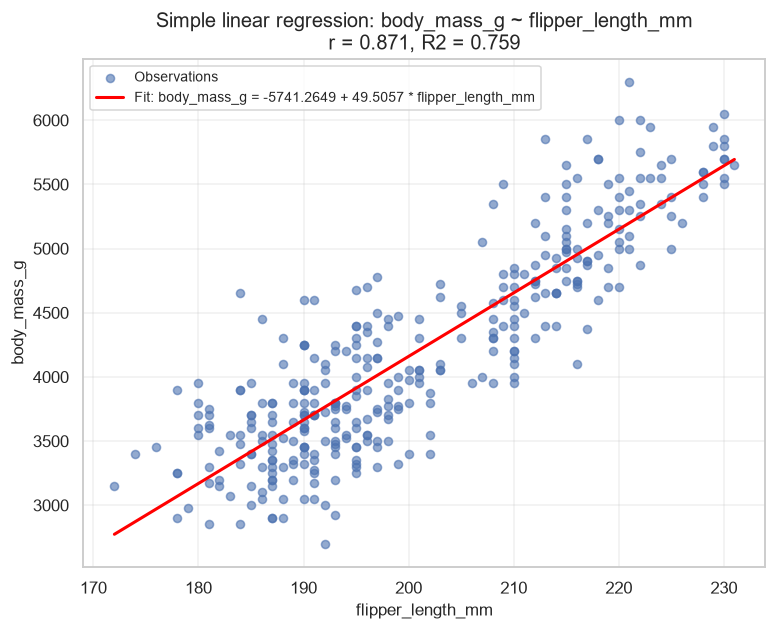

In [33]:
# --- plot 1: data + fitted regression line ---------------------
data = result["data"]
fig, ax = subplots(1, 1, (8, 6))
ax.scatter(data[X_COL], data[Y_COL], s=28, alpha=0.6, color="#4c72b0", label="Observations")
x_line = np.linspace(data[X_COL].min(), data[X_COL].max(), 100).reshape(-1, 1)
ax.plot(x_line, result["model"].predict(x_line), color="red", linewidth=2,
        label=f"Fit: {result['equation']}")
ax.set_title(f"Simple linear regression: {Y_COL} ~ {X_COL}\nr = {result['pearson_r']:.3f}, "
             f"R2 = {result['pearson_r'] ** 2:.3f}")
ax.set_xlabel(X_COL); ax.set_ylabel(Y_COL); ax.legend()
save_figure(fig, "linear_regression_fit", root=ROOT)
plt.show()


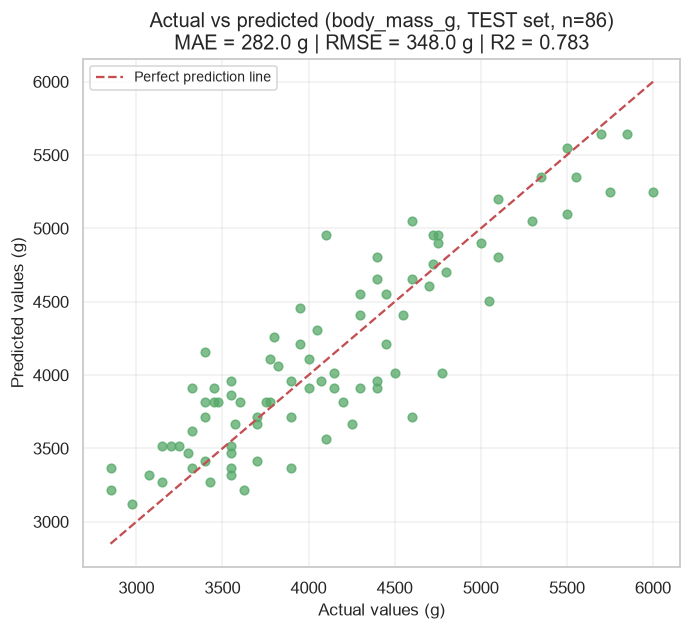

These are TEST-set metrics on unseen data, not training metrics.


In [34]:
# --- plot 2: actual vs predicted (TEST set) --------------------
fig, ax = subplots(1, 1, (7, 6))
ax.scatter(result["y_test"], result["y_pred_test"], s=32, alpha=0.75, color="#55a868")
lo = min(result["y_test"].min(), result["y_pred_test"].min())
hi = max(result["y_test"].max(), result["y_pred_test"].max())
ax.plot([lo, hi], [lo, hi], "r--", linewidth=1.5, label="Perfect prediction line")
m = result["metrics_test"]
ax.set_title(f"Actual vs predicted ({Y_COL}, TEST set, n={m['n']})\n"
             f"MAE = {m['MAE']:.1f} g | RMSE = {m['RMSE']:.1f} g | R2 = {m['R2']:.3f}")
ax.set_xlabel("Actual values (g)"); ax.set_ylabel("Predicted values (g)"); ax.legend()
save_figure(fig, "actual_vs_predicted", root=ROOT)
plt.show()
print("These are TEST-set metrics on unseen data, not training metrics.")


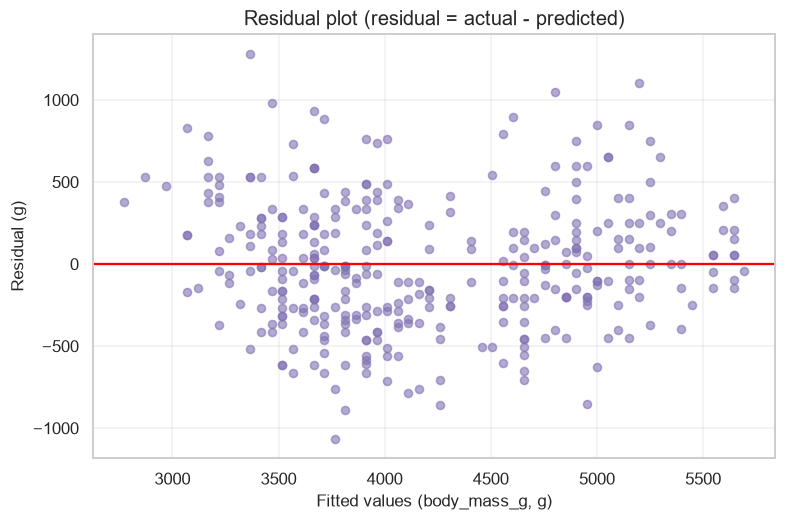

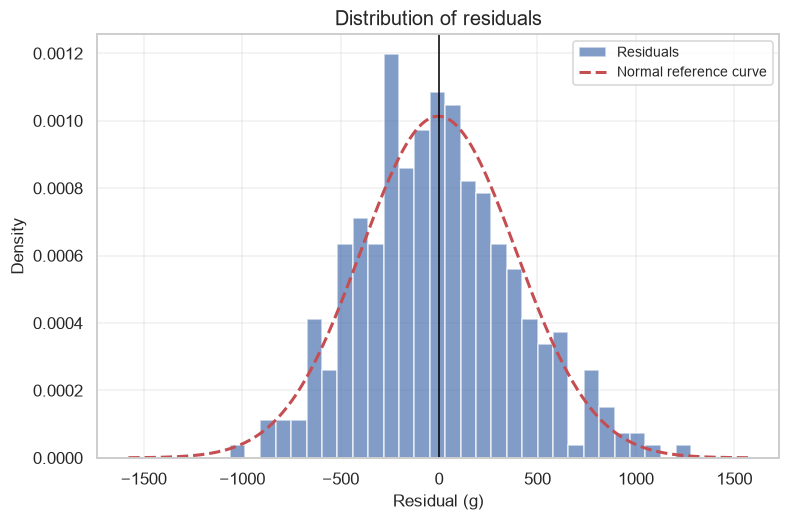

Residuals: mean = -3.430 (must be ~0), std = 393.7 g, min = -1063.8, max = 1282.2


In [35]:
# --- plots 3 & 4: residual analysis ----------------------------
fig, ax = subplots(1, 1, (8, 5))
ax.scatter(result["y_pred_full"], result["residuals_full"], s=28, alpha=0.6, color="#8172b3")
ax.axhline(0, color="red", linewidth=1.5)
ax.set_title("Residual plot (residual = actual - predicted)")
ax.set_xlabel(f"Fitted values ({Y_COL}, g)"); ax.set_ylabel("Residual (g)")
save_figure(fig, "regression_residuals", root=ROOT)
plt.show()

fig, ax = subplots(1, 1, (8, 5))
ax.hist(result["residuals_full"], bins=30, density=True, alpha=0.7,
        color="#4c72b0", edgecolor="white", label="Residuals")
x_res, y_res = distribution_analysis.normal_reference_curve(result["residuals_full"])
ax.plot(x_res, y_res, "r--", linewidth=2, label="Normal reference curve")
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Distribution of residuals")
ax.set_xlabel("Residual (g)"); ax.set_ylabel("Density"); ax.legend()
save_figure(fig, "residual_distribution", root=ROOT)
plt.show()

res = pd.Series(result["residuals_full"])
print(f"Residuals: mean = {res.mean():.3f} (must be ~0), std = {res.std():.1f} g, "
      f"min = {res.min():.1f}, max = {res.max():.1f}")


**Residual analysis:** in the residual plot the points scatter randomly around
zero with no funnel or curve, so the linear form is reasonable. The residual
histogram is roughly bell-shaped and centred at zero, which supports (but does
not prove) the normality-of-errors assumption. The classical assumptions are
linearity, independent errors, constant variance and approximately normal
residuals - none of them implies causation, and no target leakage is present
because the model only uses flipper length to predict body mass.


In [36]:
# --- single prediction inside the observed range ---------------
example_value = float(np.median(data[X_COL]))
prediction = regression_analysis.predict_for(result, example_value)
print(json.dumps(prediction, indent=2))

payload = regression_analysis.metrics_payload(result)
payload["prediction_example"] = prediction
metrics_path = regression_analysis.save_metrics(
    payload, ROOT / "outputs" / "reports" / "regression_metrics.json")
print("Saved ->", metrics_path)


{
  "input_variable": "flipper_length_mm",
  "input_value": 197.0,
  "predicted_variable": "body_mass_g",
  "predicted_value": 4011.3595919974123,
  "data_min": 172.0,
  "data_max": 231.0,
  "within_observed_range": true,
  "equation": "body_mass_g = -5741.2649 + 49.5057 * flipper_length_mm"
}
Saved -> D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\outputs\reports\regression_metrics.json


## 13. Outlier detection with the Interquartile Range (IQR)

```
Q1 = 25th percentile      Q3 = 75th percentile      IQR = Q3 - Q1
lower fence = Q1 - 1.5 x IQR        upper fence = Q3 + 1.5 x IQR
```

Values below the lower fence or above the upper fence are *potential* outliers.
They are **reported, never deleted automatically** - an outlier may be a data
error, a valid extreme observation or an important rare event.


In [37]:
# --- IQR analysis of every measurement column (pooled) ----------
report_df, outlier_detail = outlier_analysis.detect_outliers(
    cleaned, MEASUREMENT_COLS, group_col="species")

outlier_analysis.print_outlier_summary(report_df, scope="overall")
overall_rows = report_df[report_df["scope"] == "overall"]
display(overall_rows)
path = outlier_analysis.save_outlier_report(
    report_df, ROOT / "outputs" / "reports" / "outlier_report.csv")
print("Saved ->", path)


IQR OUTLIER DETECTION (overall)
bill_length_mm         fences=(    25.31,     62.41)  -> NO outlier detected (0.00%)
bill_depth_mm          fences=(    10.95,     23.35)  -> NO outlier detected (0.00%)
flipper_length_mm      fences=(   155.50,    247.50)  -> NO outlier detected (0.00%)
body_mass_g            fences=(  1750.00,   6550.00)  -> NO outlier detected (0.00%)


,scope,group,variable,n,q1,q3,iqr,lower_fence,upper_fence,n_outliers,percent_outliers,outlier_values,outlier_row_ids
0,overall,all rows,bill_length_mm,342,39.225,48.5,9.275,25.3125,62.4125,0,0.0,,
4,overall,all rows,bill_depth_mm,342,15.600,18.7,3.100,10.9500,23.3500,0,0.0,,
8,overall,all rows,flipper_length_mm,342,190.000,213.0,23.000,155.5000,247.5000,0,0.0,,
12,overall,all rows,body_mass_g,342,3550.000,4750.0,1200.000,1750.0000,6550.0000,0,0.0,,


Saved -> D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\outputs\reports\outlier_report.csv


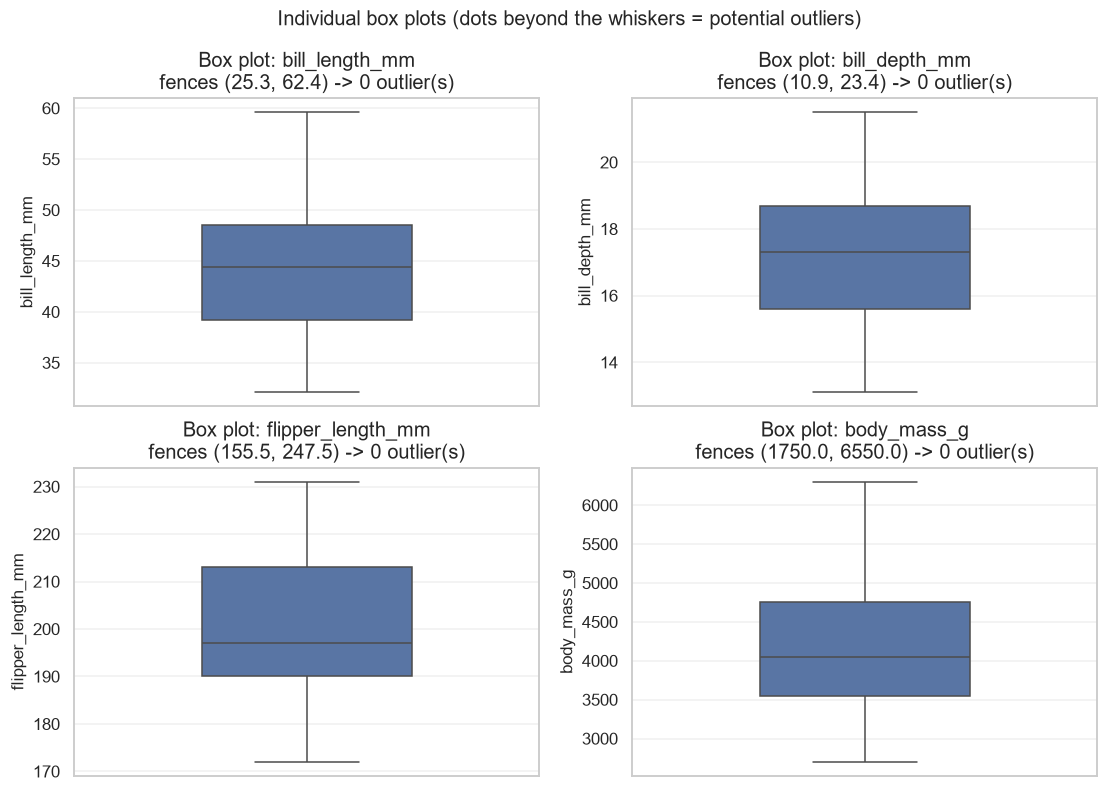

In [38]:
# --- individual box plots (one panel per variable) -------------
n = len(MEASUREMENT_COLS)
ncols, nrows = 2, int(np.ceil(n / 2))
fig, axes = subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, MEASUREMENT_COLS):
    sns.boxplot(y=cleaned[col], ax=ax, color="#4c72b0", width=0.45,
                flierprops=dict(marker="o", markersize=4, alpha=0.7))
    row = overall_rows[overall_rows["variable"] == col].iloc[0]
    ax.set_title(f"Box plot: {col}\nfences ({row['lower_fence']:.1f}, {row['upper_fence']:.1f}) "
                 f"-> {row['n_outliers']} outlier(s)")
    ax.set_ylabel(col)
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle("Individual box plots (dots beyond the whiskers = potential outliers)", fontsize=13)
save_figure(fig, "boxplot_outlier_detection", root=ROOT)
plt.show()


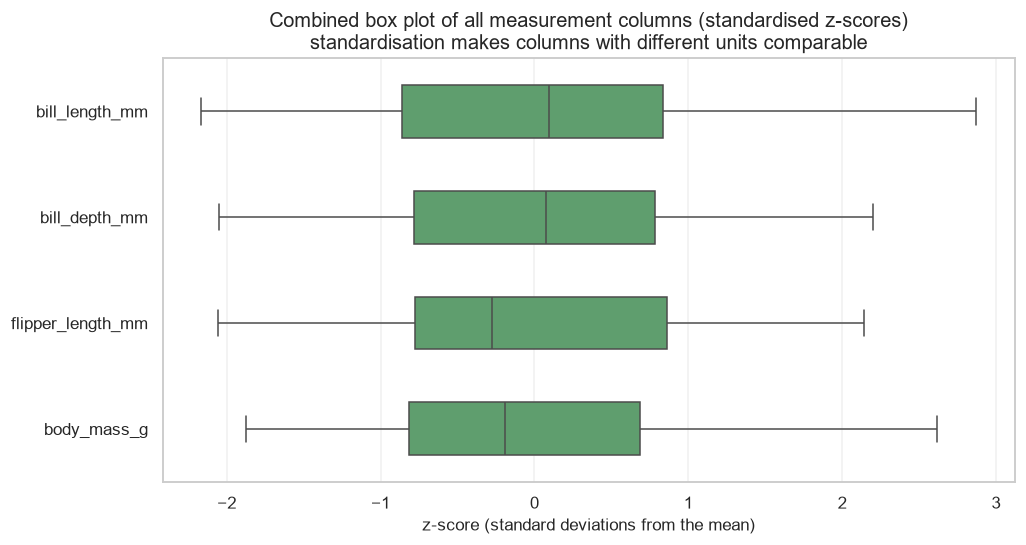

In [39]:
# --- combined box plot on a common scale (z-scores) ------------
z = (cleaned[MEASUREMENT_COLS] - cleaned[MEASUREMENT_COLS].mean()) / cleaned[MEASUREMENT_COLS].std(ddof=1)
fig, ax = subplots(1, 1, (10, 5))
sns.boxplot(data=z, orient="h", ax=ax, color="#55a868", width=0.5)
ax.set_title("Combined box plot of all measurement columns (standardised z-scores)\n"
             "standardisation makes columns with different units comparable")
ax.set_xlabel("z-score (standard deviations from the mean)")
save_figure(fig, "boxplot_all_numeric", root=ROOT)
plt.show()


In [40]:
# --- grouped detection: does species change the verdict? -------
grouped_rows = report_df[report_df["scope"] == "by_species"]
display(grouped_rows[["group", "variable", "n", "lower_fence", "upper_fence",
                      "n_outliers", "percent_outliers", "outlier_values"]])
print()
print("Pooled outliers :", int(overall_rows['n_outliers'].sum()))
print("Grouped outliers:", int(grouped_rows['n_outliers'].sum()),
      "(computed inside each species separately)")


,group,variable,n,lower_fence,upper_fence,n_outliers,percent_outliers,outlier_values
1,Adelie,bill_length_mm,151,30.7500,46.7500,0,0.000,
2,Chinstrap,bill_length_mm,68,39.2625,58.1625,0,0.000,
3,Gentoo,bill_length_mm,123,38.9250,55.9250,1,0.813,59.6
5,Adelie,bill_depth_mm,151,15.2500,21.2500,1,0.662,21.5
6,Chinstrap,bill_depth_mm,68,14.6500,22.2500,0,0.000,
7,Gentoo,bill_depth_mm,123,11.9500,17.9500,0,0.000,
9,Adelie,flipper_length_mm,151,172.5000,208.5000,2,1.325,"172, 210"
10,Chinstrap,flipper_length_mm,68,176.0000,216.0000,0,0.000,
11,Gentoo,flipper_length_mm,123,198.5000,234.5000,0,0.000,
13,Adelie,body_mass_g,151,2375.0000,4975.0000,0,0.000,



Pooled outliers : 0
Grouped outliers: 6 (computed inside each species separately)


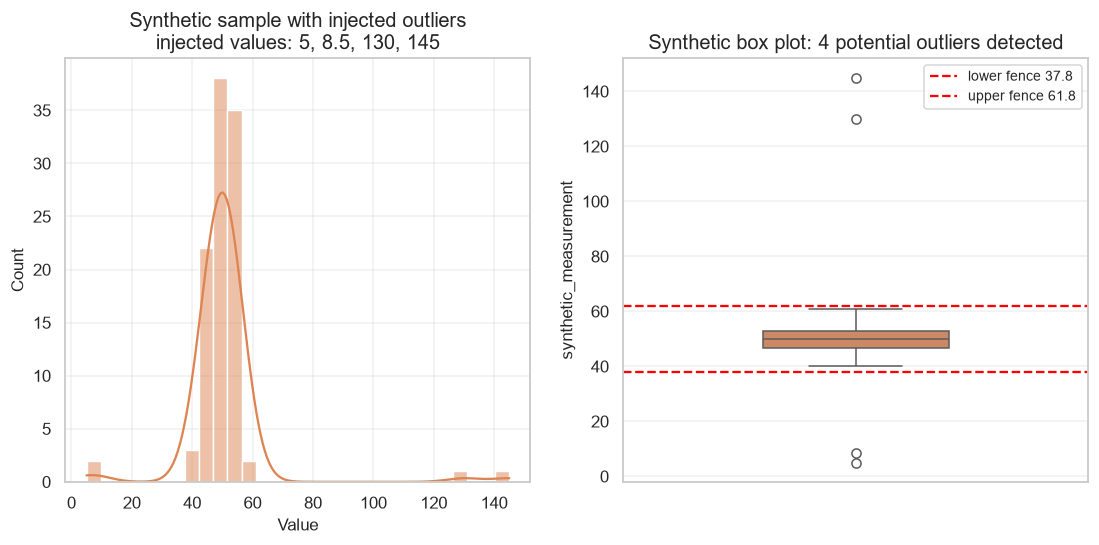

{'q1': 46.777, 'q3': 52.77, 'iqr': 5.993, 'lower_fence': 37.788, 'upper_fence': 61.759, 'n_outliers': 4, 'percent_outliers': 3.846, 'outlier_values': [5.0, 8.5, 130.0, 145.0]}


In [41]:
# --- clearly labelled SYNTHETIC outlier demonstration -----------
synth = outlier_analysis.synthetic_outlier_example()
bounds = outlier_analysis.iqr_bounds(synth)

fig, (ax1, ax2) = subplots(1, 2, figsize=(12, 5))
sns.histplot(synth, bins=30, kde=True, ax=ax1, color="#dd8452")
ax1.set_title("Synthetic sample with injected outliers\ninjected values: "
              + ", ".join(f"{v:g}" for v in synth.attrs["known_outliers"]))
ax1.set_xlabel("Value")
sns.boxplot(y=synth, ax=ax2, color="#dd8452", width=0.4)
ax2.axhline(bounds["lower_fence"], color="red", linestyle="--",
            label=f"lower fence {bounds['lower_fence']:.1f}")
ax2.axhline(bounds["upper_fence"], color="red", linestyle="--",
            label=f"upper fence {bounds['upper_fence']:.1f}")
ax2.set_title(f"Synthetic box plot: {bounds['n_outliers']} potential outliers detected")
ax2.legend()
save_figure(fig, "boxplot_synthetic_example", root=ROOT)
plt.show()

print({k: round(v, 3) if isinstance(v, float) else v
       for k, v in bounds.items() if k in ("q1", "q3", "iqr", "lower_fence", "upper_fence",
                                           "n_outliers", "percent_outliers", "outlier_values")})


**Interpretation:** pooled across all species the IQR rule finds **no** outliers
in the real data - the fences are so wide because the three species differ a lot.
Inside individual species, however, a few points do fall outside the
species-specific fences (6 points in total). This shows that outlier detection
depends on the comparison group. The synthetic example demonstrates the
mechanics clearly: 4 injected extreme values are flagged while the bulk of the
data stays inside the fences. **No outlier was removed** from the real dataset.


## 14. Additional statistical visualizations

Pair plot, violin plots, count plots and a bar chart of a categorical summary -
each with its own code, saved PNG and interpretation.


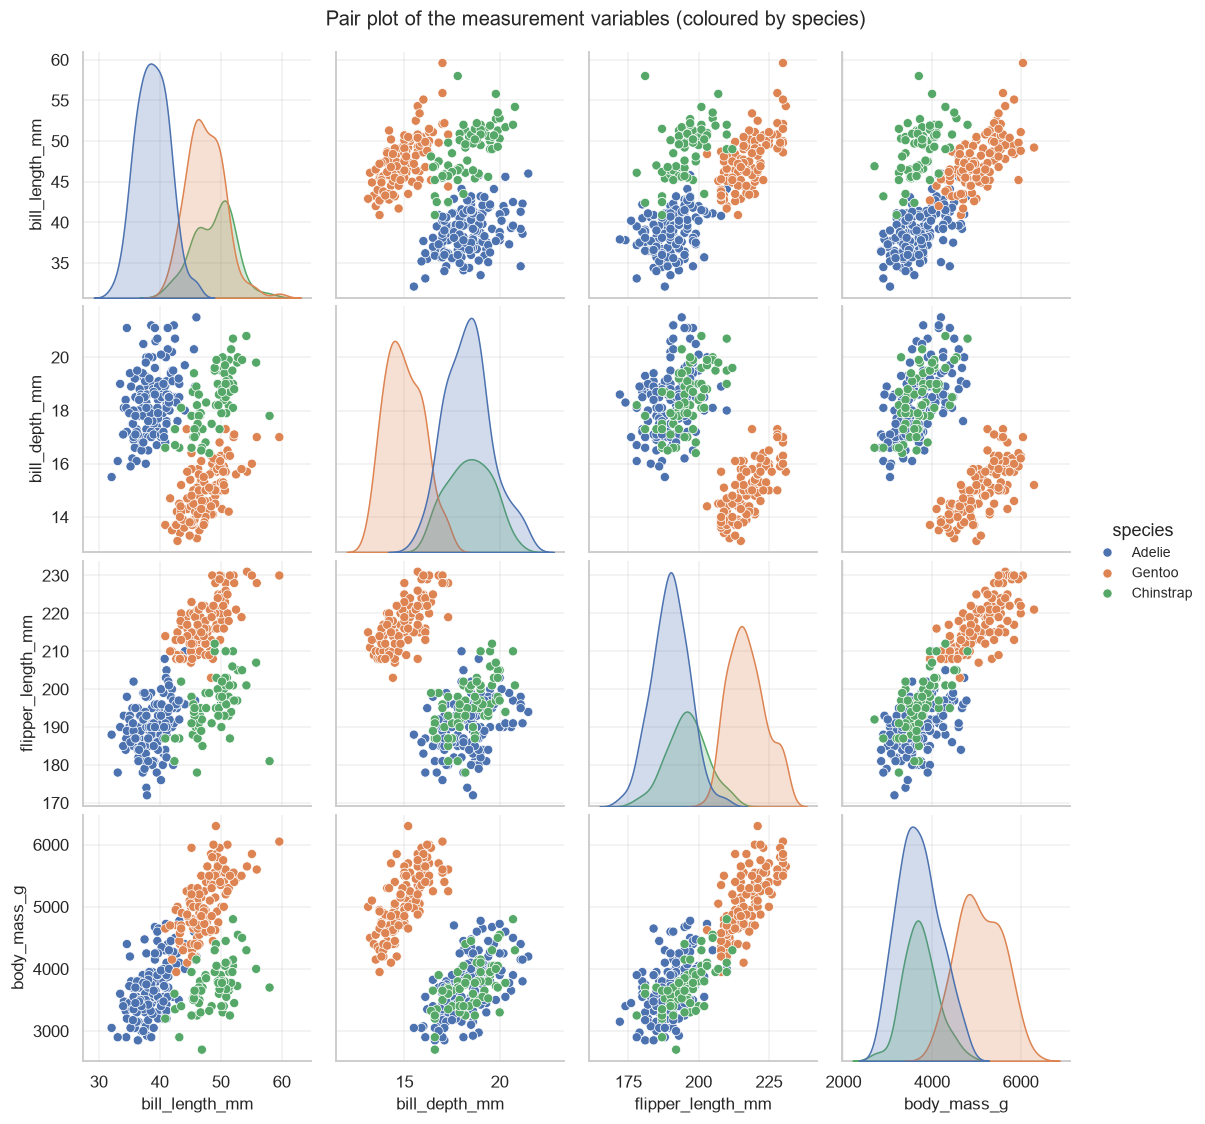

In [42]:
# --- pair plot (joint view of all measurement variables) --------
plot_cols = MEASUREMENT_COLS + [c for c in ("species",) if c in cleaned.columns]
pair_grid = sns.pairplot(cleaned[plot_cols].dropna(),
                         hue="species" if "species" in cleaned.columns else None,
                         diag_kind="kde")
pair_grid.figure.suptitle("Pair plot of the measurement variables (coloured by species)", y=1.02)
save_figure(pair_grid.figure, "pairplot", root=ROOT)
plt.show()


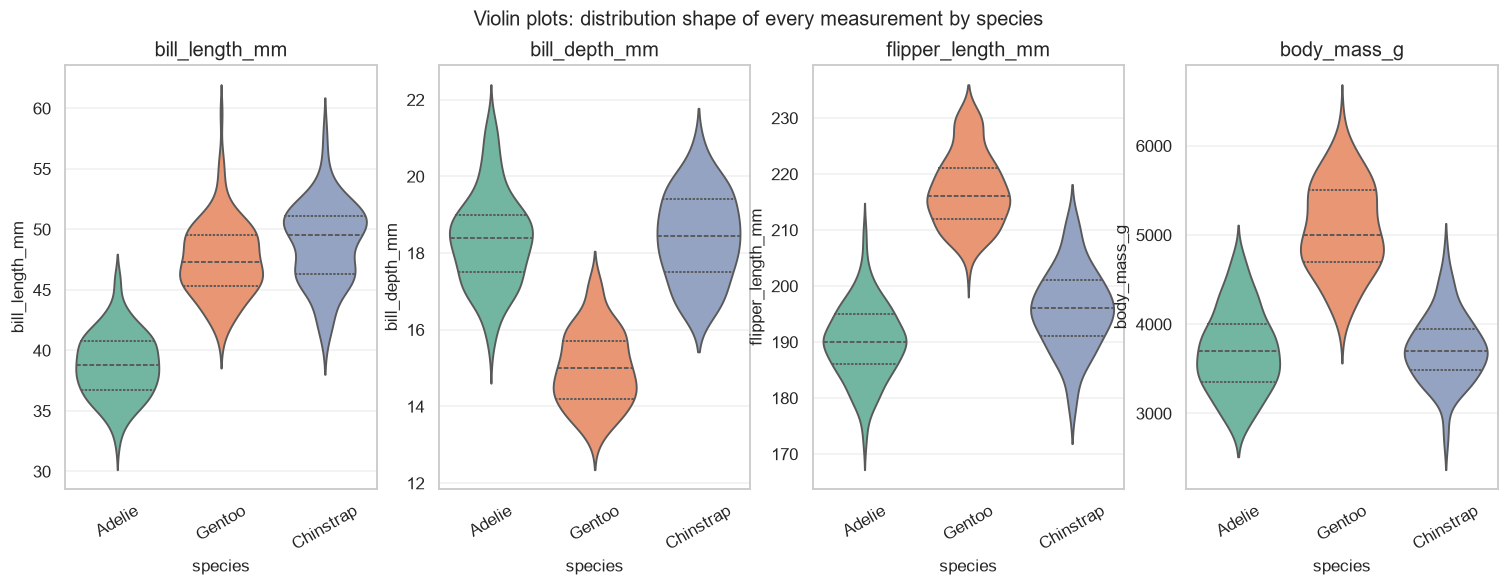

In [43]:
# --- violin plots: distribution shape per species --------------
fig, axes = subplots(1, len(MEASUREMENT_COLS), figsize=(4.2 * len(MEASUREMENT_COLS), 5))
axes = np.atleast_1d(axes).ravel()
hue = "species" if "species" in cleaned.columns else None
for ax, col in zip(axes, MEASUREMENT_COLS):
    sns.violinplot(data=cleaned, x=hue, y=col, ax=ax, inner="quartile", palette="Set2")
    ax.set_title(col)
    ax.set_xlabel(hue or "")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Violin plots: distribution shape of every measurement by species", fontsize=13)
save_figure(fig, "violin_by_species", root=ROOT)
plt.show()


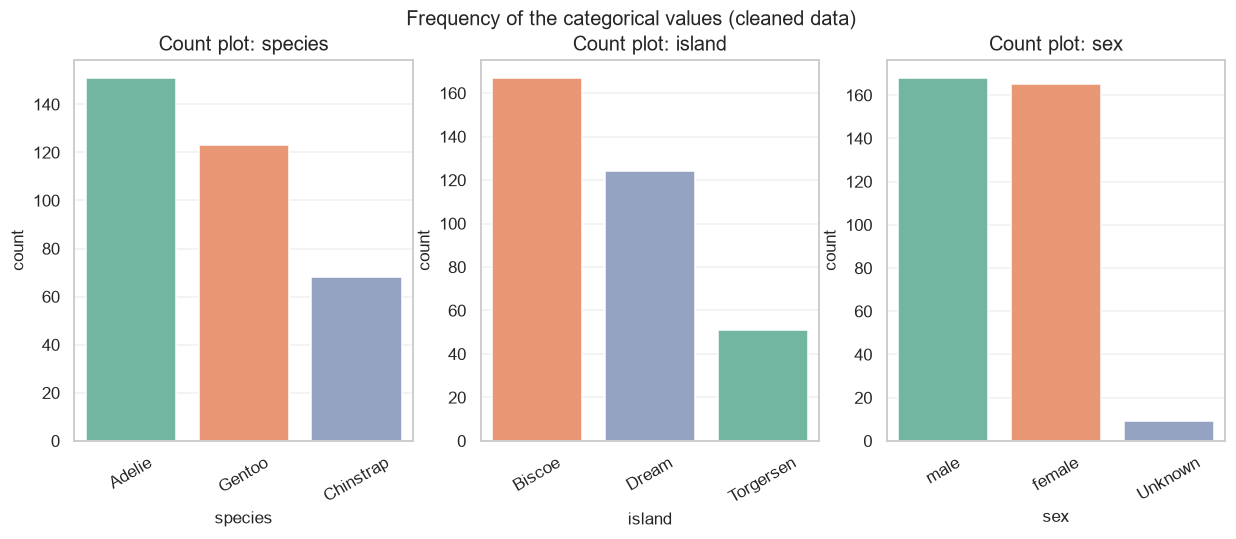

In [44]:
# --- count plots for the categorical columns -------------------
cats = [c for c in CAT_COLS if cleaned[c].nunique() <= 10]
fig, axes = subplots(1, len(cats), figsize=(4.5 * len(cats), 4.5))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, cats):
    order = cleaned[col].value_counts().index
    sns.countplot(data=cleaned, x=col, order=order, ax=ax, hue=col, palette="Set2", legend=False)
    ax.set_title(f"Count plot: {col}")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Frequency of the categorical values (cleaned data)", fontsize=13)
save_figure(fig, "countplots_categorical", root=ROOT)
plt.show()


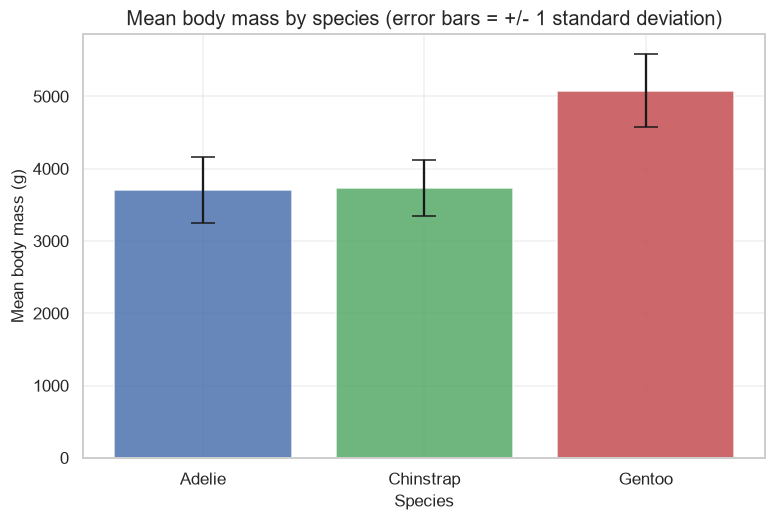

,species,mean,std
0,Adelie,3700.7,458.6
1,Chinstrap,3733.1,384.3
2,Gentoo,5076.0,504.1


In [45]:
# --- bar chart of a categorical summary ------------------------
summary = cleaned.groupby("species")["body_mass_g"].agg(["mean", "std"]).reset_index()
fig, ax = subplots(1, 1, (8, 5))
ax.bar(summary["species"], summary["mean"], yerr=summary["std"], capsize=8,
       color=["#4c72b0", "#55a868", "#c44e52"], alpha=0.85)
ax.set_title("Mean body mass by species (error bars = +/- 1 standard deviation)")
ax.set_xlabel("Species"); ax.set_ylabel("Mean body mass (g)")
save_figure(fig, "barplot_mean_mass_by_species", root=ROOT)
plt.show()
display(summary.round(1))


**Interpretation:**

* the **pair plot** shows every pairwise relationship at once; the colouring
  reveals that the three species occupy different regions of the feature space,
  which explains several pooled correlations,
* the **violin plots** show the full shape of each measurement per species -
  Gentoo penguins are clearly the heaviest with the longest flippers,
* the **count plots** show balanced sampling (species: 151/68/123; sex nearly
  equal, plus the labelled `Unknown` category created during cleaning),
* the **bar chart** summarises the same message numerically with variability
  shown by the error bars.


## 15. Findings and observations

The cell below recomputes every key number from the cleaned data, so the
findings always match the actual run (no hand-written numbers).


In [46]:
# --- dynamic findings, computed from the actual results --------
print("=" * 74)
print("KEY FINDINGS (computed from the cleaned dataset)")
print("=" * 74)
print(f"Dataset                  : {raw.shape[0]} rows x {raw.shape[1]} columns (raw)")
print(f"Cleaned dataset          : {cleaned.shape[0]} rows x {cleaned.shape[1]} columns")
print(f"Rows removed by cleaning : {cleaning_report['rows_removed']['total']}")
print()
print("Distributions (real data):")
for _, row in dist_summary.iterrows():
    print(f"  {row['variable']:<20} skew={row['skewness']:+.3f} -> {row['shape']}")
print()
print("Correlations (real data):")
for _, row in pair_table.iterrows():
    print(f"  {row['pair']:<45} r={row['pearson_r']:+.3f} p={row['p_value']:.3g} "
          f"({row['strength']} {row['direction']})")
print()
print("Regression (flipper -> mass):")
print(f"  {result['equation']}")
print(f"  r = {result['pearson_r']:.3f}, R2 = {result['pearson_r']**2:.3f}, "
      f"test RMSE = {result['metrics_test']['RMSE']:.1f} g, "
      f"test R2 = {result['metrics_test']['R2']:.3f}")
print()
print("Outliers (IQR, 1.5 x IQR fences):")
print(f"  pooled over all rows      : {int(overall_rows['n_outliers'].sum())} outlier(s)")
print(f"  computed per species      : {int(grouped_rows['n_outliers'].sum())} outlier(s)")
print(f"  removed from the data     : 0 (never delete outliers without justification)")
print("=" * 74)


KEY FINDINGS (computed from the cleaned dataset)
Dataset                  : 344 rows x 8 columns (raw)
Cleaned dataset          : 342 rows x 8 columns
Rows removed by cleaning : 2

Distributions (real data):
  bill_length_mm       skew=+0.053 -> approximately symmetric
  bill_depth_mm        skew=-0.143 -> approximately symmetric
  flipper_length_mm    skew=+0.344 -> approximately symmetric
  body_mass_g          skew=+0.468 -> approximately symmetric

Correlations (real data):
  flipper_length_mm ~ body_mass_g               r=+0.871 p=4.37e-107 (very strong positive)
  bill_length_mm ~ flipper_length_mm            r=+0.656 p=1.74e-43 (strong positive)
  bill_depth_mm ~ flipper_length_mm             r=-0.584 p=1.23e-32 (moderate negative)
  year ~ body_mass_g                            r=+0.042 p=0.437 (negligible positive)

Regression (flipper -> mass):
  body_mass_g = -5741.2649 + 49.5057 * flipper_length_mm
  r = 0.871, R2 = 0.759, test RMSE = 348.0 g, test R2 = 0.783

Outliers (IQR

### Observations

1. **Data quality:** the raw penguins table has 344 rows, 19 missing values, 0
   duplicates and no impossible values. Cleaning removed 2 rows whose every
   measurement was missing and labelled 9 unknown sexes as `Unknown`, so 342
   complete observations remain.
2. **Distributions:** all four measurements are approximately symmetric
   (|skewness| < 0.5); body mass is the most right-skewed (0.47) and bill depth
   slightly left-skewed (-0.14). None of them is bimodal *within* a species,
   but pooling species makes body mass look wider - visible in the violin plots.
3. **Relationships:** the strongest real linear relationship is
   flipper length vs body mass (r = 0.871, p < 10^-100). `year` shows no linear
   relationship with body mass (r = 0.042, p = 0.44).
4. **Simpson's paradox:** pooled, bill depth and flipper length correlate
   *negatively* (r = -0.584), yet *inside every species* the correlation is
   *positive*. The pooled sign is driven by the species mix - a classic warning
   against interpreting a correlation without checking subgroups.
5. **Regression:** body mass = -5741.26 + 49.51 x flipper length; test R2 = 0.78,
   test RMSE ~ 348 g. Residuals scatter randomly around zero.
6. **Outliers:** the pooled IQR rule flags 0 observations, while the same rule
   applied inside each species flags 6. Outliers depend on the reference group,
   and none of them was deleted.


## 16. Conclusion

The experiment met all of its objectives: the real Palmer Penguins dataset was
loaded, documented, quality-checked and cleaned with a reproducible,
fully-logged workflow; the five canonical distribution shapes were demonstrated
with seeded synthetic data and then verified on the real measurements;
relationships were visualised and quantified with Pearson's r (computed by hand
and by three libraries, agreeing to machine precision); a correlation matrix and
annotated heatmap were produced; a simple linear regression was trained on a
75 % split and honestly evaluated on the remaining 25 %; outliers were detected
with the IQR rule both pooled and per species; and a full set of additional
statistical visualizations was saved as high-resolution PNG files.

All figures, tables and reports are regenerated automatically by
`python src/run_eda.py --data data/raw/penguins.csv` - the notebook and the
script share the same core functions in `src/`.


## 17. Limitations and references

**Limitations**

* The dataset covers only one region (Palmer Station, Antarctica) and three
  breeding seasons (2007-2009), so the findings are not automatically valid for
  other penguin populations or years.
* Pearson's r and simple linear regression capture only *linear* patterns;
  non-linear or interaction effects (e.g. species x sex) are not modelled.
* Correlation is not causation - nothing here proves that a longer flipper
  *causes* a higher body mass; both may be driven by species, age or sex.
* 9 rows had an unknown sex and 2 rows had no measurements at all; the
  `Unknown` label keeps them visible but they cannot contribute to
  sex-specific analysis.
* The p-values assume approximate bivariate normality and independence of
  observations; the three measurements per year are not strictly independent
  (same colony, same season).
* The synthetic demonstrations are teaching devices, not empirical evidence.

**References**

1. Gorman KB, Williams TD, Fraser WR (2014). *Ecological sexual dimorphism and
   environmental variability within a community of Antarctic penguins (genus
   Pygoscelos)*. PLoS ONE 9(3): e109091. DOI 10.1371/journal.pone.0109091
2. Horst A (2020). *palmerpenguins: Palmer Archipelago (Antarctica) penguin
   data*. R package, CRAN. Data released under CC0 1.0.
3. Wickham H (2014). *Exploratory Data Analysis*. Had.co.nz.
4. Tukey JW (1977). *Exploratory Data Analysis*. Addison-Wesley.
5. McGrew JC Jr (2014). *Introductory Forecasts and Exploratory Data Analysis*.
6. scikit-learn documentation: `LinearRegression`,
   https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
7. SciPy documentation: `scipy.stats.pearsonr`, `scipy.stats.linregress`.


## 18. Viva questions

A list of **33 beginner-friendly viva questions with answers** (EDA basics,
distributions, skewness, correlation, p-values, regression, R-squared,
residuals, outliers, IQR, correlation vs causation, tools) is saved in:

`outputs/reports/viva_questions.md`

It is also included in the downloadable ZIP archive at the end of this notebook.


# Viva Questions and Answers — Experiment 3 (EDA)

Beginner-friendly answers for an undergraduate practical viva. The numbers quoted
are the ones produced by this project's actual run on the Palmer Penguins dataset.

---

## Basic concepts

### 1. What is EDA?
**Exploratory Data Analysis (EDA)** is the first stage of any data project. You
inspect, summarise and visualise the data *before* building models, so that you
understand its shape, quality, patterns and problems. Tools include summary
statistics, histograms, box plots, scatter plots and correlation matrices.

### 2. Why do we clean data?
Real datasets contain missing values, duplicate rows, spelling mistakes
(`"male"` vs `"MALE "`), wrong data types and impossible numbers. If we skip
cleaning, statistics are biased (e.g. averages pulled down by missing rows) and
plots become misleading. Cleaning makes the analysis reproducible and honest.

### 3. What is the difference between raw and cleaned data?
The **raw** data is the untouched original file. The **cleaned** data has
documented corrections applied. In this project the raw file
(`data/raw/penguins.csv`) is never modified; the cleaned version is written to
`data/processed/cleaned_dataset.csv`, and every decision is recorded in
`outputs/reports/data_cleaning_report.json`.

### 4. What is a missing value?
A missing value is an observation that was not recorded (empty cell, `NaN`,
`NULL`). In the penguins dataset, 2 rows have no measurements at all and 9 rows
have no recorded sex. Missing values must be handled deliberately - dropped,
labelled, or imputed - never ignored.

---

## Distributions

### 5. What is a Gaussian (normal) distribution?
A bell-shaped, symmetric distribution defined by its mean and standard
deviation. About 68 % of the data lies within 1 standard deviation of the mean,
95 % within 2 and 99.7 % within 3. Many natural measurements (heights, exam
scores of large classes) are approximately normal. Mean = median = mode.

### 6. What is a uniform distribution?
Every value in an interval has (approximately) the same probability - the
histogram is flat. Example: rolling a fair die, or `np.random.uniform(0, 100)`.
The mean sits in the middle of the interval.

### 7. What is skewness?
Skewness measures the **asymmetry** of a distribution.
- **Right-skewed (positive skew)**: long tail on the right, mean > median.
  Example: household incomes.
- **Left-skewed (negative skew)**: long tail on the left, mean < median.
  Example: scores in a very easy exam (most students near 100).
Rule of thumb: |skewness| < 0.5 ≈ symmetric.

### 8. What is a bimodal distribution?
A distribution with **two peaks**, which usually means two sub-groups were
pooled together (e.g. male and female penguin body masses, or morning and
evening traffic). Plotting the data coloured by group reveals the hidden
structure.

### 9. What is a histogram?
A bar chart of how many observations fall into equal-width bins. It shows the
*shape* of a distribution. The height is a count (or a density).

### 10. What is a KDE plot?
A **Kernel Density Estimate** is a smooth curve that approximates the
probability density of the data. It is like a histogram drawn with a continuous
curve, so peaks and skew are easier to see.

### 11. What is a Q-Q plot?
A **quantile-quantile plot** compares the quantiles of your data with the
quantiles of a theoretical normal distribution. If the points follow the
straight red line, the data is approximately normal; S-shaped curves indicate
skew or heavy tails.

---

## Relationships and correlation

### 12. What is a scatter plot?
A plot of one dot per observation using two numerical variables (x on the
horizontal axis, y on the vertical). It reveals the direction, strength and
form of a relationship, plus unusual points.

### 13. What is correlation?
Correlation is a measure of how two numerical variables change *together*.
Positive correlation: both tend to rise together. Negative: one rises while the
other falls. Zero: no **linear** co-movement.

### 14. What is Pearson's correlation coefficient (r)?
Pearson's *r* is a number between −1 and +1 that measures the strength and
direction of the **linear** relationship between two continuous variables:

```
r = Σ((x − x̄)(y − ȳ)) / sqrt( Σ(x − x̄)² · Σ(y − ȳ)² )
```

It is computed here with `scipy.stats.pearsonr`, `numpy.corrcoef`,
`DataFrame.corr()` and by hand with NumPy - all give the same answer.

### 15. What does r = +1 mean?
A **perfect positive linear relationship**: all points lie exactly on an
upward-sloping straight line. Doubling x always increases y by a fixed amount.

### 16. What does r = −1 mean?
A **perfect negative linear relationship**: all points lie exactly on a
downward-sloping straight line.

### 17. What does r = 0 mean?
There is **no linear** relationship. It does **not** mean the variables are
independent - a strong curved (non-linear) relationship can also give r ≈ 0.
This experiment demonstrates that with a parabola: r ≈ 0 although y = x² exactly.

### 18. How do we interpret the strength of r?
Rules of thumb (configurable, not universal laws): |r| ≥ 0.8 very strong,
0.6–0.8 strong, 0.4–0.6 moderate, 0.2–0.4 weak, < 0.2 negligible. Context
matters: r = 0.5 can be huge in social sciences and tiny in physics.

### 19. What is a p-value in correlation testing?
The p-value is the probability of observing a correlation at least this strong
in a random sample **if the true population correlation were zero**. A small
p-value (e.g. < 0.05) means the correlation is unlikely to be a pure sampling
accident. In this dataset, flipper length vs body mass has p ≈ 10⁻¹⁰⁷ -
extremely significant.

### 20. What is a correlation heatmap?
A matrix of correlation coefficients rendered as colours - typically red for
positive, blue for negative and white near zero, centred at 0. It lets you scan
many variable pairs at once. Ours is `outputs/plots/pearson_correlation_heatmap.png`.

### 21. What is the difference between correlation and causation?
Correlation only says two variables move together; a **third variable** or
coincidence can create the pattern. Causation requires a plausible mechanism
and usually a controlled experiment. Example: ice-cream sales and drowning are
correlated - the sun (temperature) is the cause. **Never claim causation from a
correlation or a small p-value alone.**

---

## Regression

### 22. What is linear regression?
A method that finds the straight line that best predicts one numerical variable
(**target**) from another (**predictor**):

```
y_hat = b0 + b1 * x
```

`b0` is the intercept (predicted y when x = 0) and `b1` is the slope (change in
predicted y for a one-unit increase in x).

### 23. What are slope and intercept?
In this dataset the fitted equation is
`body_mass_g = -5741.26 + 49.51 × flipper_length_mm`, so every extra millimetre
of flipper length is associated with about **49.5 g** more body mass. The
intercept (−5741 g) is not physically meaningful - a 0 mm flipper penguin does
not exist - it only anchors the line.

### 24. What is R-squared?
R² is the fraction of the variance in the target explained by the model (0 to
1). In simple regression R² = r². Our model: r = 0.871, R² ≈ 0.76, so about
76 % of the variation in body mass is associated with flipper length. It never
proves the model is *correct*.

### 25. What are residuals?
A residual is `actual − predicted` for one observation. The residual plot shows
residuals against fitted values; for a good linear model they should scatter
randomly around 0 with no clear pattern. A funnel shape suggests heteroscedasticity.

### 26. Why use a train/test split?
If you evaluate a model on the same rows it was trained on, the metrics are
optimistic. We fit on 75 % of the penguins and evaluate on the unseen 25 %
(test RMSE ≈ 348 g, R² ≈ 0.78) - an honest estimate of performance on new data.

---

## Outliers

### 27. What is an outlier?
An observation that lies far away from the rest of the data. It may be a
measurement error, a data-entry mistake, or a genuine and important rare event
(e.g. the heaviest penguin ever recorded).

### 28. What is the IQR?
The **Interquartile Range** is `IQR = Q3 − Q1`, the width of the middle 50 % of
the data. Tukey's fences are `Q1 − 1.5×IQR` and `Q3 + 1.5×IQR`; values outside
are *potential* outliers (also drawn as points on a box plot).

### 29. Why should outliers not always be removed?
Blind deletion shrinks variance, biases means and hides real phenomena. An
outlier must be investigated: if it is a proven error it can be corrected or
removed with documentation; if it is real it should be kept (or analysed
separately). This project **reports** outliers and never deletes them.

### 30. Can a dataset have no outliers?
Yes. In the penguins data, applying the 1.5×IQR rule to the pooled
measurements flags **0** outliers, yet within individual species 6 points fall
outside the species-specific fences. This shows that outlier detection depends
on the group you compare against.

---

## Tools and workflow

### 31. What is pandas / NumPy / Matplotlib / Seaborn / SciPy / scikit-learn?
- **pandas**: tables (DataFrames), loading CSVs, summary statistics.
- **NumPy**: fast arrays and numerical maths.
- **Matplotlib**: low-level plotting (histograms, scatter, lines).
- **Seaborn**: high-level statistical plots on top of Matplotlib.
- **SciPy**: statistical tests (`pearsonr`, `linregress`, skewness).
- **scikit-learn**: machine learning tools (`LinearRegression`, train/test split).

### 32. Why fix a random seed?
`random_state = 42` makes random steps (synthetic data, train/test split)
identical every run, so the notebook, the reports and the figures are exactly
reproducible.

### 33. What is the difference between this notebook and `src/run_eda.py`?
Both call the **same** Python functions in `src/`. The notebook shows every step
with inline plots and explanations; `python src/run_eda.py --data data/raw/penguins.csv`
re-runs the entire experiment from the command line and rebuilds all outputs.


## 19. Package all deliverables

Everything produced by this notebook (plots, reports, cleaned data, scripts,
README, this notebook) is packed into one ZIP archive. In Google Colab the
download starts automatically; locally the path is printed.


In [47]:
# --- package plots, reports, cleaned data, scripts and this notebook ---
zip_path = ROOT / "outputs" / "eda_experiment3_outputs.zip"
include_folders = [
    ROOT / "outputs" / "plots", ROOT / "outputs" / "reports", ROOT / "outputs" / "logs",
    ROOT / "data" / "processed", ROOT / "data" / "raw", ROOT / "src", ROOT / "tests",
]
optional_files = [ROOT / "EXPERIMENT 3.ipynb", ROOT / "README.md",
                  ROOT / "requirements.txt", ROOT / ".gitignore"]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in include_folders:
        if folder.exists():
            for file in sorted(folder.rglob("*")):
                if file.is_file() and "__pycache__" not in file.parts \
                        and file.suffix not in {".pyc", ".pyo"}:
                    zf.write(file, file.relative_to(ROOT))
    for file in optional_files:
        if file.exists():
            zf.write(file, file.relative_to(ROOT))

print("ZIP archive created:", zip_path, f"({zip_path.stat().st_size / 1e6:.2f} MB)")
print()
print("Contents:")
with zipfile.ZipFile(zip_path) as zf:
    for name in zf.namelist():
        print("  ", name)
print()
print("No API token, credential file or secret configuration is included in the ZIP.")

# --- Colab convenience: start downloads -------------------------------------
if IS_COLAB:
    try:
        from google.colab import files  # type: ignore
        print("\nDownloading the ZIP archive ...")
        files.download(str(zip_path))
    except Exception as exc:  # never let a download stop the run
        print("Automatic download skipped:", exc)
        print("The archive is also available at:", zip_path)


ZIP archive created: D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-3\outputs\eda_experiment3_outputs.zip (8.50 MB)

Contents:
   outputs/plots/actual_vs_predicted.png
   outputs/plots/barplot_mean_mass_by_species.png
   outputs/plots/boxplot_all_numeric.png
   outputs/plots/boxplot_outlier_detection.png
   outputs/plots/boxplot_synthetic_example.png
   outputs/plots/correlation_no_linear.png
   outputs/plots/correlation_perfect_negative.png
   outputs/plots/correlation_perfect_positive.png
   outputs/plots/correlation_strong_negative.png
   outputs/plots/correlation_strong_positive.png
   outputs/plots/correlation_weak_negative.png
   outputs/plots/correlation_weak_positive.png
   outputs/plots/countplots_categorical.png
   outputs/plots/dataset_distributions.png
   outputs/plots/dataset_qq_plots.png
   outputs/plots/distribution_bimodal.png
   outputs/plots/distribution_gaussian.png
   outputs/plots/distribution_left_skewed.png
   outputs/plots/distribution_right_skewed.pn

In [48]:
# --- individual downloads / quick access (optional) -------------------------
targets = [
    ROOT / "data" / "processed" / "cleaned_dataset.csv",
    ROOT / "outputs" / "reports" / "data_cleaning_report.json",
    ROOT / "outputs" / "reports" / "pearson_correlation_matrix.csv",
    ROOT / "outputs" / "reports" / "regression_metrics.json",
    ROOT / "outputs" / "reports" / "outlier_report.csv",
    ROOT / "outputs" / "reports" / "viva_questions.md",
]
print("Key deliverables:")
for target in targets:
    size = f"{target.stat().st_size / 1024:.1f} KB" if target.exists() else "MISSING"
    print(f"  {str(target.relative_to(ROOT)):<55} {size}")

if IS_COLAB:
    # A blocking input() would stop "Runtime -> Run all", so the choice is read
    # from an environment variable instead.  Opt in with:
    #     os.environ["EDA_DOWNLOAD_INDIVIDUAL"] = "y"
    if os.environ.get("EDA_DOWNLOAD_INDIVIDUAL", "n").strip().lower() == "y":
        from google.colab import files  # type: ignore
        for target in targets:
            if target.exists():
                files.download(str(target))
    else:
        print("\nIndividual downloads are switched off (nothing blocks the run).")
        print("Every file above is saved under", ROOT / "outputs", "and", ROOT / "data")
else:
    print("\nRun the whole experiment again from the command line with:")
    print("    python src/run_eda.py --data data/raw/penguins.csv --output outputs")
    print("Re-running the notebook or the script overwrites previous outputs (no duplicates).")


Key deliverables:
  data\processed\cleaned_dataset.csv                      16.7 KB
  outputs\reports\data_cleaning_report.json               7.4 KB
  outputs\reports\pearson_correlation_matrix.csv          0.3 KB
  outputs\reports\regression_metrics.json                 1.4 KB
  outputs\reports\outlier_report.csv                      1.4 KB
  outputs\reports\viva_questions.md                       9.9 KB

Run the whole experiment again from the command line with:
    python src/run_eda.py --data data/raw/penguins.csv --output outputs
Re-running the notebook or the script overwrites previous outputs (no duplicates).


### Running this experiment elsewhere

**Google Colab** - upload only this notebook (*File -> Upload notebook*) and
use *Runtime -> Run all*. The notebook restores `src/` and the dataset from the
archive embedded in it, installs any missing library, detects Colab and offers
the finished ZIP at the end. No other file has to be uploaded.

**Kaggle** - create a new notebook, attach this project ZIP (or a dataset with
`penguins.csv`) as an *Input dataset*, then run top-to-bottom. The notebook
detects Kaggle, reads the CSV from `/kaggle/input/` (no download if already
mounted) and writes everything under `/kaggle/working/`. To use the Kaggle API
locally, place your credentials in `~/.kaggle/kaggle.json` with permissions 600
and never commit that file (it is listed in `.gitignore`).

**Local Python**

```
pip install -r requirements.txt
python src/run_eda.py --data data/raw/penguins.csv --output outputs
pytest                 # optional: run the automated tests
```
